# Prediksi Penjualan Harian Toko Ritel Favorita (Ekuador)
### Mini Project Data Science & Generative AI — Kategori **Regression** (Time Series)
**Dataset:** Kaggle *Store Sales - Time Series Forecasting* · **Kelompok 7** · Celerates Independent Study

## 0. Deskripsi Project & Pembagian Peran

**Tujuan.** Membangun model regresi untuk meramalkan `sales` (penjualan harian per toko per kategori produk) pada horizon **15 hari ke depan**, membandingkan beberapa algoritma, lalu menjelaskan faktor apa saja yang mendorong penjualan.

**Prinsip penilaian yang kami ikuti:** yang dinilai adalah *proses dan pemahaman* (EDA, alasan memilih algoritma/metrik, interpretasi), bukan tingginya skor.

| Anggota | Bagian yang dipegang |
|---|---|
| **Samudra Tsalasa Putra** | 0, 1, 9, 12, 13 + integrasi akhir & uji *Restart & Run All* |
| **Dwi Aura Ningrum** | 3 (EDA), 5 (Preprocessing & Split) |
| **Anavalis Ridho Abdee Nugroho** | 6 (Pemilihan Algoritma), 7.2 Ridge, 7.4 LightGBM, 7.6 Tuning |
| **Hany Nadya Fairuz** | 7.1 Baseline, 7.3 Random Forest, 7.5 Cross-Validation, 8 (Evaluasi), 10 (Interpretasi) |
| **Eka Lidya Rahmadini** | 2 (Setup & Loading), 4 (Feature Engineering) |
| **Selsa Trikartika** | 11 (Forecast 15 hari, submission, fungsi plot & mini-app Streamlit) |

> Pembagian ini hanya penanda kepemilikan bagian. Semua anggota tetap harus memahami seluruh alur karena penilaian menekankan pemahaman.

### Daftar Isi
1. Business Understanding
2. Setup & Data Loading
3. Data Understanding & EDA
4. Feature Engineering
5. Preprocessing & Split Berbasis Waktu
6. Pemilihan Algoritma
7. Modeling, Cross-Validation & Tuning
8. Evaluasi Model
9. Pemilihan Model Terbaik
10. Interpretasi Model
11. Forecast 15 Hari ke Depan (opsional)
12. Kesimpulan & Insight Bisnis
13. Referensi

### Cara menjalankan
1. Pastikan akun Kaggle sudah **Join Competition** `store-sales-time-series-forecasting` (atau letakkan file CSV/zip di folder kerja dan isi `DATA_DIR`).
2. Atur konfigurasi di sel **2.2** (terutama `SAMPLE_STORES` dan `START_DATE` bila memori terbatas).
3. Jalankan *Restart & Run All*. Semua grafik penting otomatis tersimpan di folder `figures/`.

## 1. Business Understanding
*Penanggung jawab: Samudra Tsalasa Putra*

**Konteks.** Corporación Favorita adalah jaringan supermarket di Ekuador. Data berisi penjualan harian 33 kategori produk (`family`) di 54 toko. Peramalan penjualan dipakai untuk:
- **Stok & rantai pasok:** menghindari kehabisan barang (*stockout*) maupun penumpukan stok.
- **Perencanaan tenaga kerja & promosi:** menyesuaikan jumlah staf dan jadwal promo dengan hari ramai.
- **Persiapan hari khusus:** libur nasional, tanggal gajian (15 dan akhir bulan; gaji sektor publik), dan kejadian luar biasa (gempa 16 April 2016).

**Target:** `sales` (kontinu, nilai ≥ 0, bisa pecahan karena ada produk yang dijual per kilogram).

**Biaya salah prediksi.**
- *Under-forecast* (ramalan terlalu rendah) → stok habis, penjualan hilang, pelanggan kecewa.
- *Over-forecast* (ramalan terlalu tinggi) → stok menumpuk, barang segar (mis. `PRODUCE`, `DAIRY`) berisiko busuk.
Karena kedua arah merugikan, kami memakai metrik yang menghukum selisih secara simetris pada skala relatif.

**Pilihan metrik (dijelaskan lebih lengkap di Bagian 8).**
- **RMSLE (metrik utama):** error dihitung pada skala logaritmik, sehingga yang dinilai adalah *selisih relatif*. Cocok karena `sales` sangat miring (ada toko/kategori bernilai ratusan ribu dan banyak yang nol), dan dipakai juga oleh kompetisi aslinya.
- **MAE & RMSE:** dalam satuan asli (unit penjualan), mudah dipahami bisnis; RMSE lebih sensitif terhadap lonjakan besar.
- **R²:** proporsi variasi yang dijelaskan model.
- **WAPE:** total error absolut dibagi total penjualan, alternatif MAPE yang aman terhadap nilai nol.
- MAPE **tidak dipakai** karena pembagian oleh `sales = 0`.

## 2. Setup & Data Loading
*Penanggung jawab: Eka Lidya Rahmadini*

**Tujuan:** menyiapkan library, konfigurasi, dan memuat semua tabel dengan tipe data hemat memori.

**Urutan pencarian data (otomatis):**
1. Folder lokal yang sudah berisi CSV (`DATA_DIR`, `./data`, atau folder kerja).
2. File zip `store-sales-time-series-forecasting.zip` di folder kerja (otomatis di-*extract*).
3. `kagglehub.competition_download(...)` (butuh autentikasi Kaggle dan sudah **Join Competition**).

In [ ]:
# 2.1 Instalasi library yang belum tersedia
import sys, subprocess, importlib

def pastikan(paket, modul=None):
    try:
        importlib.import_module(modul or paket)
    except ImportError:
        print(f"Memasang {paket} ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", paket])

for p in ["lightgbm", "shap", "statsmodels", "kagglehub"]:
    try:
        pastikan(p)
    except Exception as e:
        print("Gagal memasang", p, "->", e)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# 2.2 Import library & KONFIGURASI
import os, glob, time, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, make_scorer
import lightgbm as lgb

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

# ---------------- KONFIGURASI ----------------
DATA_DIR      = "/content/drive/MyDrive/Mini Project_Kelompok 7_DSGA/store-sales-time-series-forecasting"
SAMPLE_STORES = None        # None = semua 54 toko; atau list, mis. [1, 10, 24, 44, 47, 52] agar lebih ringan
START_DATE    = "2015-01-01"  # data MODEL dimulai dari tanggal ini (EDA tetap memakai seluruh data)
VAL_DAYS      = 15          # panjang validasi = horizon test (15 hari); maksimal 16 agar tidak leakage
N_CV_SPLITS   = 3           # jumlah lipatan TimeSeriesSplit
RF_MAX_ROWS   = 200_000     # Random Forest dilatih pada sampel baris training (lihat Bagian 7.3)
TUNE_ROWS     = 400_000     # jumlah baris terbaru yang dipakai untuk tuning
N_ITER_TUNING = 8           # jumlah kombinasi RandomizedSearchCV
RUN_SHAP      = True        # False untuk melewati SHAP bila lambat
# ------------------------------------------------------------

FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

def simpan_fig(nama):
    """Simpan grafik aktif ke folder figures/ lalu tampilkan."""
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, f"{nama}.png"), dpi=120, bbox_inches="tight")
    plt.show()

print("Konfigurasi:", dict(SAMPLE_STORES=SAMPLE_STORES, START_DATE=START_DATE, VAL_DAYS=VAL_DAYS))

Konfigurasi: {'SAMPLE_STORES': None, 'START_DATE': '2015-01-01', 'VAL_DAYS': 15}


In [ ]:
# 2.3 Menemukan folder data (lokal -> zip -> kagglehub)
def punya_data(folder):
    return folder is not None and os.path.exists(os.path.join(folder, "train.csv"))

def siapkan_folder_data():
    # 1) Folder lokal yang sudah berisi CSV
    for f in [DATA_DIR, "data", "."]:
        if punya_data(f):
            print("Memakai folder lokal:", os.path.abspath(f)); return f
    # 2) File zip di folder kerja / DATA_DIR
    kandidat_zip = glob.glob("*store-sales*.zip")
    if DATA_DIR and os.path.isdir(DATA_DIR):
        kandidat_zip += glob.glob(os.path.join(DATA_DIR, "*.zip"))
    for z in kandidat_zip:
        print("Mengekstrak", z, "-> ./data")
        with zipfile.ZipFile(z) as zf:
            zf.extractall("data")
        if punya_data("data"):
            return "data"
    # 3) kagglehub (butuh akun Kaggle yang sudah Join Competition)
    try:
        import kagglehub
        # kagglehub.login()   # <- hapus tanda # bila diminta autentikasi (atau set KAGGLE_USERNAME & KAGGLE_KEY)
        path = kagglehub.competition_download("store-sales-time-series-forecasting")
        print("Data diunduh ke:", path)
        if punya_data(path):
            return path
        print("File yang ada di folder unduhan:", os.listdir(path))
    except Exception as e:
        print("Unduhan kagglehub gagal:", repr(e))
    raise FileNotFoundError(
        "Data tidak ditemukan. Pastikan sudah Join Competition & autentikasi Kaggle, "
        "ATAU taruh file CSV/zip di folder kerja, ATAU isi DATA_DIR di sel 2.2.")

DATA = siapkan_folder_data()
print("File tersedia:", sorted(f for f in os.listdir(DATA) if f.endswith(".csv")))

Memakai folder lokal: /content/drive/MyDrive/Mini Project_Kelompok 7_DSGA/store-sales-time-series-forecasting
File tersedia: ['holidays_events.csv', 'oil.csv', 'sample_submission.csv', 'stores.csv', 'test.csv', 'train.csv', 'transactions.csv']


In [ ]:
# 2.4 Memuat semua tabel dengan tipe data hemat memori
train = pd.read_csv(f"{DATA}/train.csv", parse_dates=["date"],
                    dtype={"id": "int32", "store_nbr": "int16", "family": "category",
                           "sales": "float32", "onpromotion": "int16"})
test = pd.read_csv(f"{DATA}/test.csv", parse_dates=["date"],
                   dtype={"id": "int32", "store_nbr": "int16", "family": "category", "onpromotion": "int16"})
stores = pd.read_csv(f"{DATA}/stores.csv")
oil = pd.read_csv(f"{DATA}/oil.csv", parse_dates=["date"])
holidays = pd.read_csv(f"{DATA}/holidays_events.csv", parse_dates=["date"])
transactions = pd.read_csv(f"{DATA}/transactions.csv", parse_dates=["date"])

tabel = {"train": train, "test": test, "stores": stores, "oil": oil,
         "holidays_events": holidays, "transactions": transactions}
ringkas = pd.DataFrame({n: {"baris": d.shape[0], "kolom": d.shape[1],
                            "kolom_daftar": ", ".join(d.columns)} for n, d in tabel.items()}).T
display(ringkas)

kamus = pd.DataFrame([
    ("train", "store_nbr", "ID toko (1-54)"),
    ("train", "family", "Kategori produk yang dijual (33 kategori)"),
    ("train", "sales", "TARGET: total penjualan kategori di toko pada tanggal tsb (bisa pecahan)"),
    ("train", "onpromotion", "Jumlah item dalam kategori yang sedang dipromosikan"),
    ("test", "(sama dengan train)", "15 hari setelah tanggal terakhir train, TANPA kolom sales"),
    ("stores", "city, state, type, cluster", "Lokasi toko, tipe toko (A-E), dan cluster toko serupa"),
    ("oil", "dcoilwtico", "Harga minyak harian (Ekuador sangat bergantung pada minyak)"),
    ("holidays_events", "type, locale, locale_name, transferred",
     "Jenis hari libur/event, cakupan (National/Regional/Local), dan apakah libur dipindahkan pemerintah"),
    ("transactions", "transactions", "Jumlah transaksi harian per toko"),
], columns=["tabel", "kolom", "arti"])
display(kamus)
print("Rentang train:", train.date.min().date(), "s/d", train.date.max().date())
print("Rentang test :", test.date.min().date(), "s/d", test.date.max().date())

,baris,kolom,kolom_daftar
train,3000888,6,"id, date, store_nbr, family, sales, onpromotion"
test,28512,5,"id, date, store_nbr, family, onpromotion"
stores,54,5,"store_nbr, city, state, type, cluster"
oil,1218,2,"date, dcoilwtico"
holidays_events,350,6,"date, type, locale, locale_name, description, ..."
transactions,83488,3,"date, store_nbr, transactions"


,tabel,kolom,arti
0,train,store_nbr,ID toko (1-54)
1,train,family,Kategori produk yang dijual (33 kategori)
2,train,sales,TARGET: total penjualan kategori di toko pada ...
3,train,onpromotion,Jumlah item dalam kategori yang sedang dipromo...
4,test,(sama dengan train),"15 hari setelah tanggal terakhir train, TANPA ..."
5,stores,"city, state, type, cluster","Lokasi toko, tipe toko (A-E), dan cluster toko..."
6,oil,dcoilwtico,Harga minyak harian (Ekuador sangat bergantung...
7,holidays_events,"type, locale, locale_name, transferred","Jenis hari libur/event, cakupan (National/Regi..."
8,transactions,transactions,Jumlah transaksi harian per toko


Rentang train: 2013-01-01 s/d 2017-08-15
Rentang test : 2017-08-16 s/d 2017-08-31


### Interpretasi Bagian 2
- `train.csv` adalah tabel utama berukuran jutaan baris (satu baris = 1 toko × 1 kategori × 1 tanggal). Tipe data sudah dihemat (`int16`, `float32`, `category`).
- `test.csv` **tidak memiliki** kolom `sales`, sehingga **tidak bisa dipakai untuk menghitung error**. Seluruh evaluasi memakai *split berbasis waktu* dari `train.csv` (Bagian 5). `test.csv` hanya dipakai di Bagian 11 untuk membuat ramalan 15 hari ke depan.
- `transactions.csv` tidak disebut di deskripsi kompetisi tetapi tersedia; kami membahas risiko *leakage*-nya di Bagian 4.

## 3. Data Understanding & EDA
*Penanggung jawab: Dwi Aura Ningrum*

**Tujuan:** memahami struktur data, kualitas data (missing value, duplikat, outlier), pola waktu, dan pengaruh faktor eksternal (promosi, minyak, libur, gempa) sebelum modeling. EDA memakai **seluruh data** agar pola jangka panjang terlihat.

In [ ]:
# 3.1 Struktur data & statistik deskriptif
train.info(memory_usage="deep")
display(train.describe().T)
print(f"\nJumlah toko: {train.store_nbr.nunique()} | jumlah family: {train.family.nunique()} | "
      f"jumlah deret waktu (toko x family): {train.groupby(['store_nbr','family'], observed=True).ngroups}")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000888 entries, 0 to 3000887
Data columns (total 6 columns):
 #   Column       Dtype         
---  ------       -----         
 0   id           int32         
 1   date         datetime64[ns]
 2   store_nbr    int16         
 3   family       category      
 4   sales        float32       
 5   onpromotion  int16         
dtypes: category(1), datetime64[ns](1), float32(1), int16(2), int32(1)
memory usage: 60.1 MB


,count,mean,min,25%,50%,75%,max,std
id,3000888.0,1500443.5,0.0,750221.75,1500443.5,2250665.25,3000887.0,866281.891642
date,3000888,2015-04-24 08:27:04.703088384,2013-01-01 00:00:00,2014-02-26 18:00:00,2015-04-24 12:00:00,2016-06-19 06:00:00,2017-08-15 00:00:00,NaN
store_nbr,3000888.0,27.5,1.0,14.0,27.5,41.0,54.0,15.585787
sales,3000888.0,357.775726,0.0,0.0,11.0,195.847252,124717.0,1092.777832
onpromotion,3000888.0,2.60277,0.0,0.0,0.0,0.0,741.0,12.218882



Jumlah toko: 54 | jumlah family: 33 | jumlah deret waktu (toko x family): 1782


In [ ]:
# 3.2 Missing value pada semua tabel
def ringkas_missing(df):
    m = df.isna().sum()
    return pd.DataFrame({"jumlah_missing": m, "persen": (m / len(df) * 100).round(2)})

for nama, d in tabel.items():
    r = ringkas_missing(d)
    print(f"--- {nama}: total missing = {int(r.jumlah_missing.sum())}")
    if r.jumlah_missing.sum() > 0:
        display(r[r.jumlah_missing > 0])

# Menelusuri missing value harga minyak
oil_na = oil[oil.dcoilwtico.isna()]
print("\nContoh tanggal oil kosong:", oil_na.date.dt.date.head(5).tolist())
print("Hari dalam seminggu tanggal oil kosong (0=Senin):", oil_na.date.dt.dayofweek.value_counts().to_dict())

--- train: total missing = 0
--- test: total missing = 0
--- stores: total missing = 0
--- oil: total missing = 43


,jumlah_missing,persen
dcoilwtico,43,3.53


--- holidays_events: total missing = 0
--- transactions: total missing = 0

Contoh tanggal oil kosong: [datetime.date(2013, 1, 1), datetime.date(2013, 1, 21), datetime.date(2013, 2, 18), datetime.date(2013, 3, 29), datetime.date(2013, 5, 27)]
Hari dalam seminggu tanggal oil kosong (0=Senin): {0: 23, 4: 9, 3: 7, 1: 2, 2: 2}


**Strategi missing value (dijelaskan alasannya):**
- `train`, `test`, `stores`, `holidays_events`: tidak ada missing value pada kolom yang dipakai.
- `oil.dcoilwtico`: kosong terutama pada hari libur bursa/akhir pekan. Harga minyak berlaku "sampai ada harga baru", maka kami memakai **forward-fill**, lalu *back-fill* untuk baris paling awal. Interpolasi linear tidak dipilih karena mengarang harga di antara dua hari perdagangan.
- Nilai kosong akibat *lag* di awal deret (Bagian 4) bukan kesalahan data: LightGBM menanganinya secara native, sedangkan Ridge dan Random Forest memakai imputasi median yang di-*fit* hanya pada data train.

In [ ]:
# 3.3 Duplikat & tanggal yang hilang
dup = train.duplicated(["date", "store_nbr", "family"]).sum()
print("Baris duplikat (date, store_nbr, family):", dup)

semua_hari = pd.date_range(train.date.min(), train.date.max())
hari_hilang = semua_hari.difference(pd.DatetimeIndex(train.date.unique()))
print("Jumlah tanggal kalender:", len(semua_hari), "| tanggal unik di train:", train.date.nunique())
print("Tanggal yang hilang dari train:", [d.strftime("%Y-%m-%d") for d in hari_hilang])
print("Variasi jumlah baris per tanggal:", train.groupby("date").size().value_counts().to_dict())
print("Duplikat pada holidays_events (date, description):", holidays.duplicated(["date", "description"]).sum())
print("Sales negatif:", int((train.sales < 0).sum()))

Baris duplikat (date, store_nbr, family): 0
Jumlah tanggal kalender: 1688 | tanggal unik di train: 1684
Tanggal yang hilang dari train: ['2013-12-25', '2014-12-25', '2015-12-25', '2016-12-25']
Variasi jumlah baris per tanggal: {1782: 1684}
Duplikat pada holidays_events (date, description): 0
Sales negatif: 0


**Interpretasi duplikat & tanggal hilang.** Periksa hasil di atas: tidak ada duplikat kunci `(date, store_nbr, family)`, dan tanggal yang hilang adalah hari Natal (25 Desember) tiap tahun, yaitu toko tutup. Keputusan kami: tanggal tersebut **tidak diisi** pada data latih (tidak ada pengamatan), tetapi kalender lengkap tetap dibangun di Bagian 4 supaya `lag` dihitung berdasarkan *jumlah hari* yang benar, bukan berdasarkan jumlah baris.

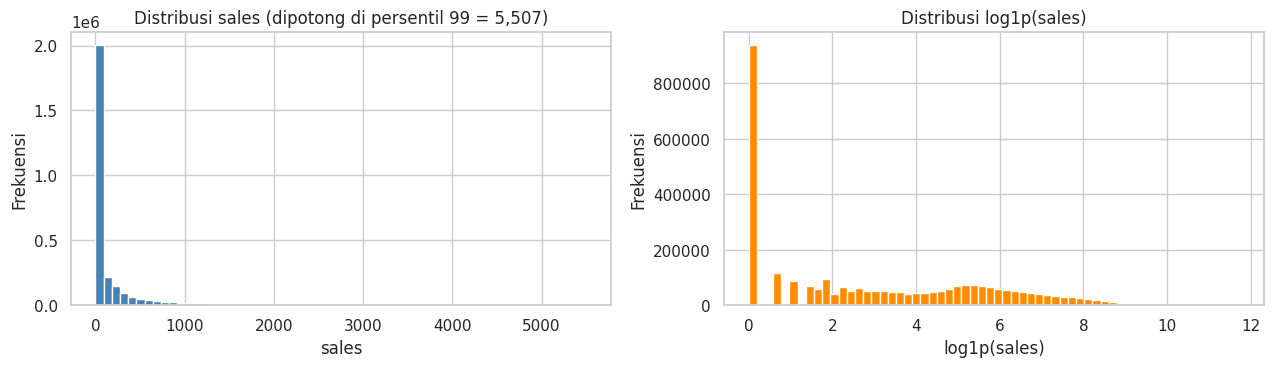

Proporsi sales = 0: 31.3%
Skewness sebelum log1p: 7.36 | sesudah log1p: 0.41


In [ ]:
# 3.4 Distribusi target & proporsi sales = 0
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
p99 = train.sales.quantile(0.99)
ax[0].hist(train.sales[train.sales <= p99], bins=60, color="steelblue")
ax[0].set_title(f"Distribusi sales (dipotong di persentil 99 = {p99:,.0f})")
ax[0].set_xlabel("sales"); ax[0].set_ylabel("Frekuensi")
ax[1].hist(np.log1p(train.sales), bins=60, color="darkorange")
ax[1].set_title("Distribusi log1p(sales)")
ax[1].set_xlabel("log1p(sales)"); ax[1].set_ylabel("Frekuensi")
simpan_fig("01_distribusi_sales")

print(f"Proporsi sales = 0: {(train.sales == 0).mean():.1%}")
print(f"Skewness sebelum log1p: {train.sales.skew():.2f} | sesudah log1p: {np.log1p(train.sales).skew():.2f}")

**Interpretasi.** Distribusi `sales` sangat miring ke kanan dengan ekor panjang dan sangat banyak nol, sedangkan `log1p(sales)` jauh lebih simetris (bandingkan nilai skewness yang dicetak). Karena itu kami **melatih model pada `log1p(sales)`** dan mengembalikannya dengan `expm1`. Ini juga membuat metrik RMSLE setara dengan RMSE pada target yang sudah ditransformasi.

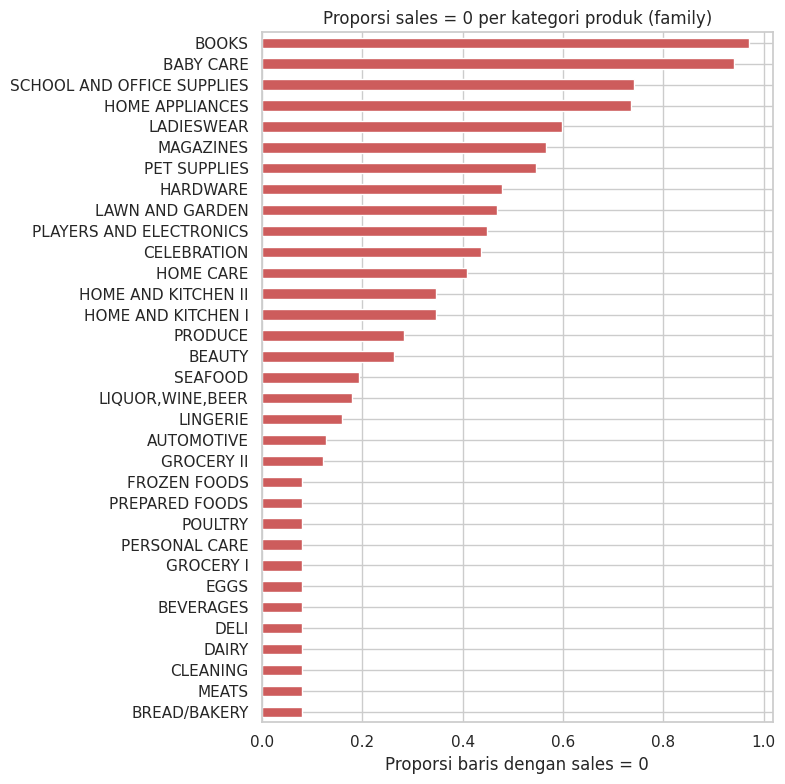

Jumlah deret (toko x family) yang TOTAL sales-nya nol: 53
Toko yang baru mencatat penjualan > 30 hari setelah awal data: {20: '2015-02-13', 21: '2015-07-24', 22: '2015-10-09', 29: '2015-03-20', 36: '2013-05-09', 42: '2015-08-21', 52: '2017-04-20', 53: '2014-05-29'}


In [ ]:
# 3.5 Dari mana sales = 0 berasal? (kategori tidak dijual vs toko belum buka)
nol_family = (train.sales == 0).groupby(train.family, observed=True).mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 8))
nol_family.plot.barh(ax=ax, color="indianred")
ax.invert_yaxis()
ax.set_title("Proporsi sales = 0 per kategori produk (family)")
ax.set_xlabel("Proporsi baris dengan sales = 0"); ax.set_ylabel("")
simpan_fig("02_proporsi_nol_per_family")

# Deret waktu yang seluruhnya nol & toko yang baru mulai berjualan belakangan
total_deret = train.groupby(["store_nbr", "family"], observed=True)["sales"].sum()
print("Jumlah deret (toko x family) yang TOTAL sales-nya nol:", int((total_deret == 0).sum()))

penjualan_pertama = train[train.sales > 0].groupby("store_nbr")["date"].min()
terlambat = penjualan_pertama[penjualan_pertama > train.date.min() + pd.Timedelta(days=30)]
print("Toko yang baru mencatat penjualan > 30 hari setelah awal data:",
      {int(k): v.strftime("%Y-%m-%d") for k, v in terlambat.items()})

**Interpretasi.** Nol punya tiga sumber: (1) kategori yang memang jarang/tidak dijual (mis. kategori dengan proporsi nol tinggi pada grafik), (2) deret yang seluruhnya nol di toko tertentu, (3) toko yang baru dibuka sehingga belum ada penjualan di awal periode. Nol ini **bukan data rusak**, melainkan informasi bisnis. Kami mempertahankannya dan memberi model fitur `zero_share_28` (porsi hari nol pada 28 hari terakhir) agar model bisa membedakan "produk memang tidak laku" dari "produk laku tapi hari ini sepi".

,Q1,Q3,batas_atas_IQR,persen_di_atas_batas,max
family,,,,,
SCHOOL AND OFFICE SUPPLIES,1.0,7.0,16.0,10.3,1332.0
BABY CARE,1.0,2.0,3.5,10.1,116.0
PRODUCE,283.8,2415.0,5611.7,8.5,17850.6
SEAFOOD,4.4,36.3,84.2,8.2,274.4
PREPARED FOODS,38.0,130.1,268.3,8.2,912.6
HOME APPLIANCES,1.0,2.0,3.5,8.0,15.0
FROZEN FOODS,45.0,185.6,396.4,7.7,14541.5
HOME AND KITCHEN II,9.0,29.0,59.0,7.6,1568.0
"LIQUOR,WINE,BEER",29.0,127.0,274.0,7.5,4821.0


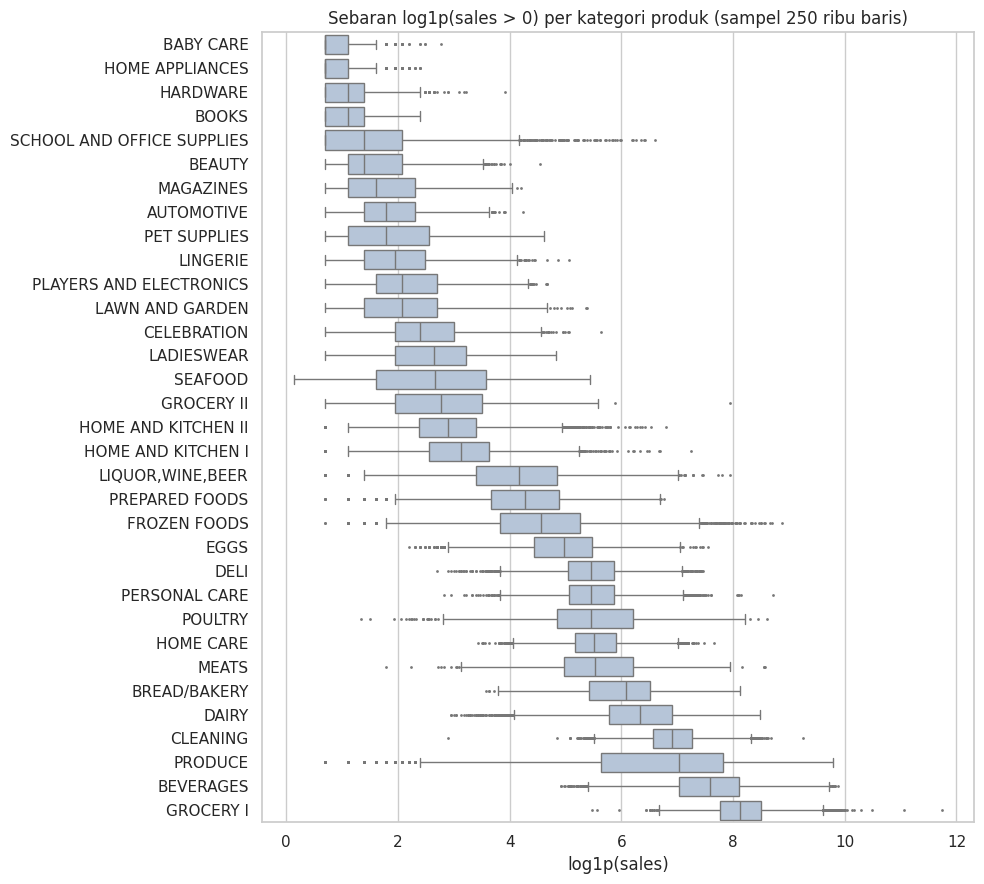

In [ ]:
# 3.6 Outlier sales per family (IQR pada penjualan > 0, karena banyak family didominasi nol)
def ringkas_iqr(s):
    s = s[s > 0]
    q1, q3 = s.quantile([0.25, 0.75])
    batas = q3 + 1.5 * (q3 - q1)
    return pd.Series({"Q1": q1, "Q3": q3, "batas_atas_IQR": batas,
                      "persen_di_atas_batas": (s > batas).mean() * 100, "max": s.max()})

tabel_iqr = train.groupby("family", observed=True)["sales"].apply(ringkas_iqr).unstack().round(1)
display(tabel_iqr.sort_values("persen_di_atas_batas", ascending=False).head(10))

contoh = train[train.sales > 0].sample(250_000, random_state=SEED)
urut = contoh.groupby("family", observed=True)["sales"].median().sort_values().index
fig, ax = plt.subplots(figsize=(10, 9))
sns.boxplot(data=contoh.assign(log_sales=np.log1p(contoh.sales)), y="family", x="log_sales",
            order=urut, ax=ax, fliersize=1, color="lightsteelblue")
ax.set_title("Sebaran log1p(sales > 0) per kategori produk (sampel 250 ribu baris)")
ax.set_xlabel("log1p(sales)"); ax.set_ylabel("")
simpan_fig("03_boxplot_outlier_per_family")

**Keputusan outlier: dipertahankan, tidak dibuang atau di-*winsorize*.** Nilai ekstrem pada data ini umumnya **sinyal nyata** (kategori volume besar seperti `GROCERY I`, `BEVERAGES`, `PRODUCE`, hari ramai menjelang akhir tahun). Membuangnya akan membuat model buta terhadap lonjakan yang justru penting bagi stok. Pengaruh ekornya sudah diredam oleh transformasi `log1p`, dan model berbasis pohon tidak sensitif terhadap skala outlier. Perhatikan tabel IQR: persentase di atas batas bervariasi antar kategori, sehingga batas global tunggal tidak cocok dipakai.

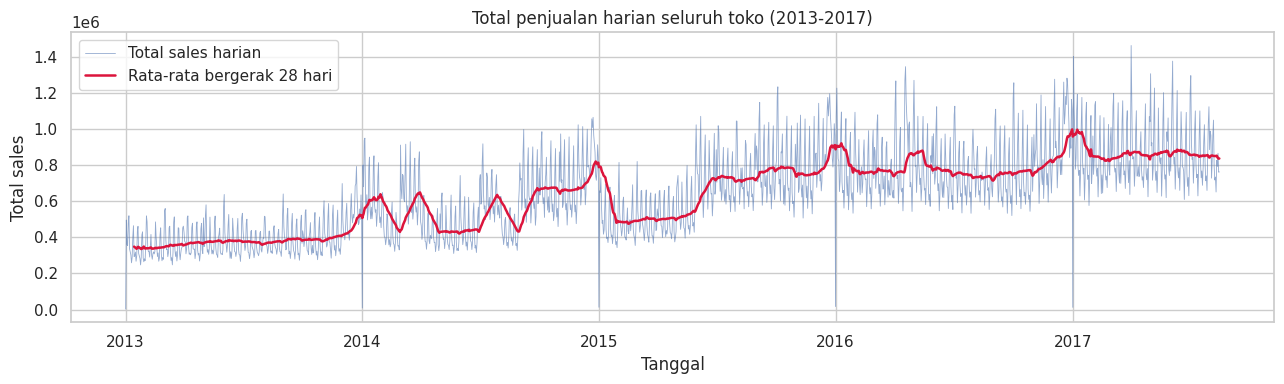

In [ ]:
# 3.7 Tren total penjualan harian
harian = train.groupby("date").agg(sales=("sales", "sum"), promo=("onpromotion", "sum")).reset_index()
harian["ma28"] = harian.sales.rolling(28, min_periods=14).mean()

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(harian.date, harian.sales, lw=0.6, alpha=0.6, label="Total sales harian")
ax.plot(harian.date, harian.ma28, color="crimson", lw=1.8, label="Rata-rata bergerak 28 hari")
ax.set_title("Total penjualan harian seluruh toko (2013-2017)")
ax.set_xlabel("Tanggal"); ax.set_ylabel("Total sales"); ax.legend()
simpan_fig("04_tren_total_sales")

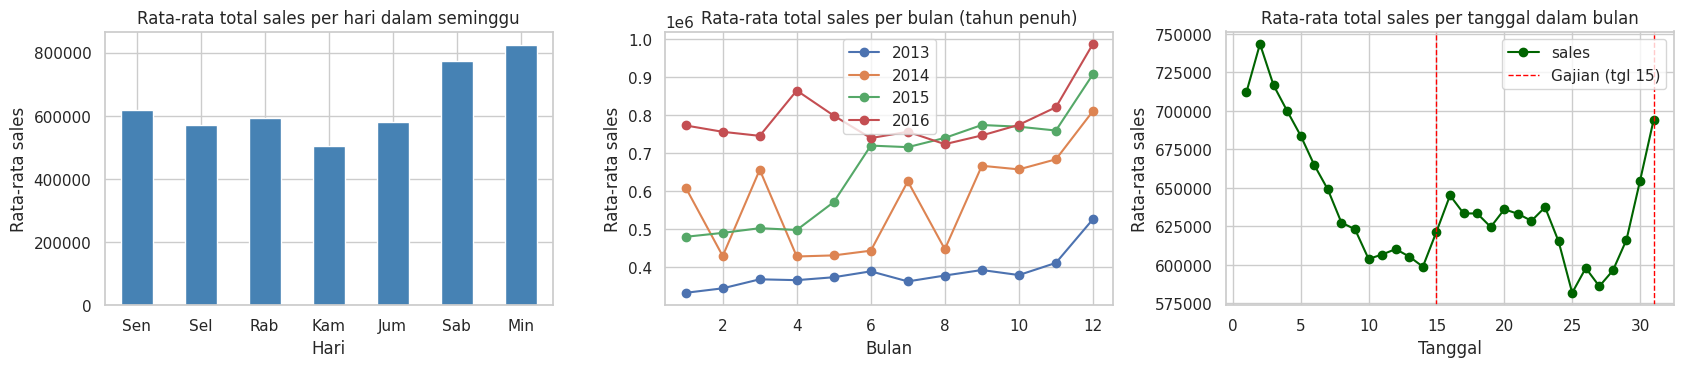

Hari paling ramai: Min | paling sepi: Kam (rasio ramai/sepi = 1.63x)


In [ ]:
# 3.8 Pola musiman: hari dalam seminggu, bulan, dan tanggal gajian
h = harian[harian.sales > 0].copy()
h["hari_minggu"] = h.date.dt.dayofweek
h["bulan"] = h.date.dt.month
h["tahun"] = h.date.dt.year
h["hari_bulan"] = h.date.dt.day

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
nama_hari = ["Sen", "Sel", "Rab", "Kam", "Jum", "Sab", "Min"]
h.groupby("hari_minggu").sales.mean().plot.bar(ax=ax[0], color="steelblue")
ax[0].set_xticklabels(nama_hari, rotation=0)
ax[0].set_title("Rata-rata total sales per hari dalam seminggu"); ax[0].set_xlabel("Hari"); ax[0].set_ylabel("Rata-rata sales")

for t, g in h[h.tahun.between(2013, 2016)].groupby("tahun"):
    ax[1].plot(g.groupby("bulan").sales.mean(), marker="o", label=str(t))
ax[1].set_title("Rata-rata total sales per bulan (tahun penuh)"); ax[1].set_xlabel("Bulan"); ax[1].set_ylabel("Rata-rata sales"); ax[1].legend()

h.groupby("hari_bulan").sales.mean().plot(ax=ax[2], marker="o", color="darkgreen")
ax[2].axvline(15, color="red", ls="--", lw=1, label="Gajian (tgl 15)"); ax[2].axvline(31, color="red", ls="--", lw=1)
ax[2].set_title("Rata-rata total sales per tanggal dalam bulan"); ax[2].set_xlabel("Tanggal"); ax[2].set_ylabel("Rata-rata sales"); ax[2].legend()
simpan_fig("05_pola_musiman")

hari_ter = h.groupby("hari_minggu").sales.mean()
print(f"Hari paling ramai: {nama_hari[hari_ter.idxmax()]} | paling sepi: {nama_hari[hari_ter.idxmin()]} "
      f"(rasio ramai/sepi = {hari_ter.max()/hari_ter.min():.2f}x)")

**Interpretasi.** Periksa tiga panel: (1) ada pola **mingguan** yang jelas (hari tertentu konsisten lebih ramai), (2) ada **musiman tahunan** dengan lonjakan di akhir tahun, (3) ada pola di sekitar **tanggal gajian** (15 dan akhir bulan). Ketiganya menjadi dasar fitur kalender (`hari_minggu`, `bulan`, `is_payday`, dst.) dan alasan kami memakai *lag* kelipatan 7 hari. Tren naik jangka panjang pada grafik 3.7 berarti model tidak boleh hanya mengandalkan tahun/tanggal absolut; fitur *lag* dan *rolling* menangkap level terkini.

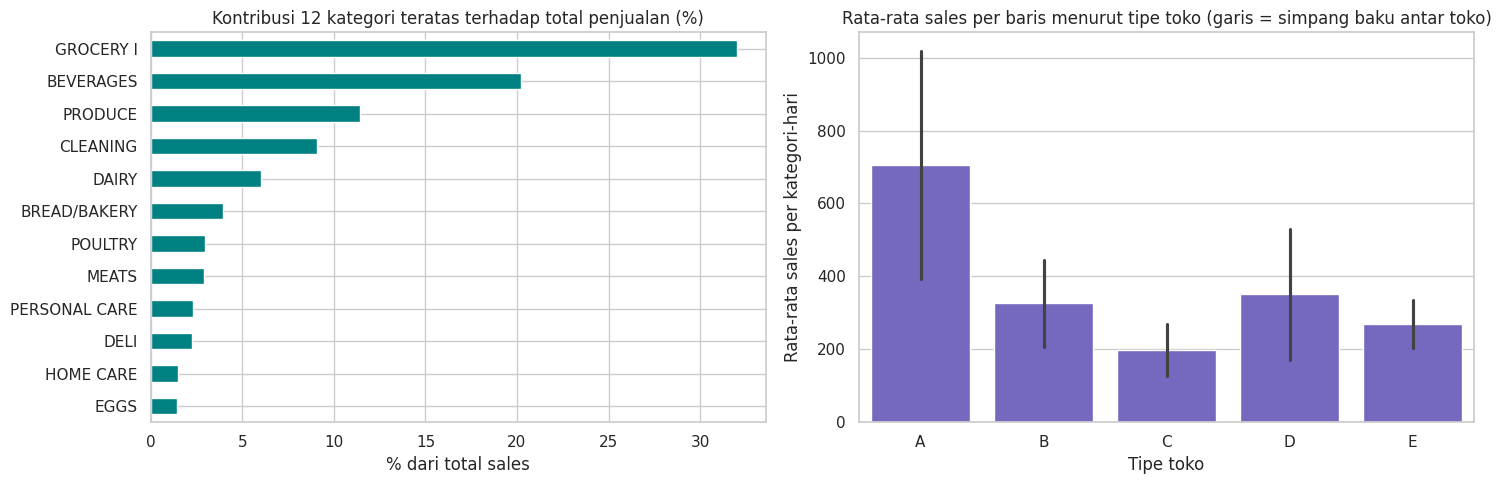

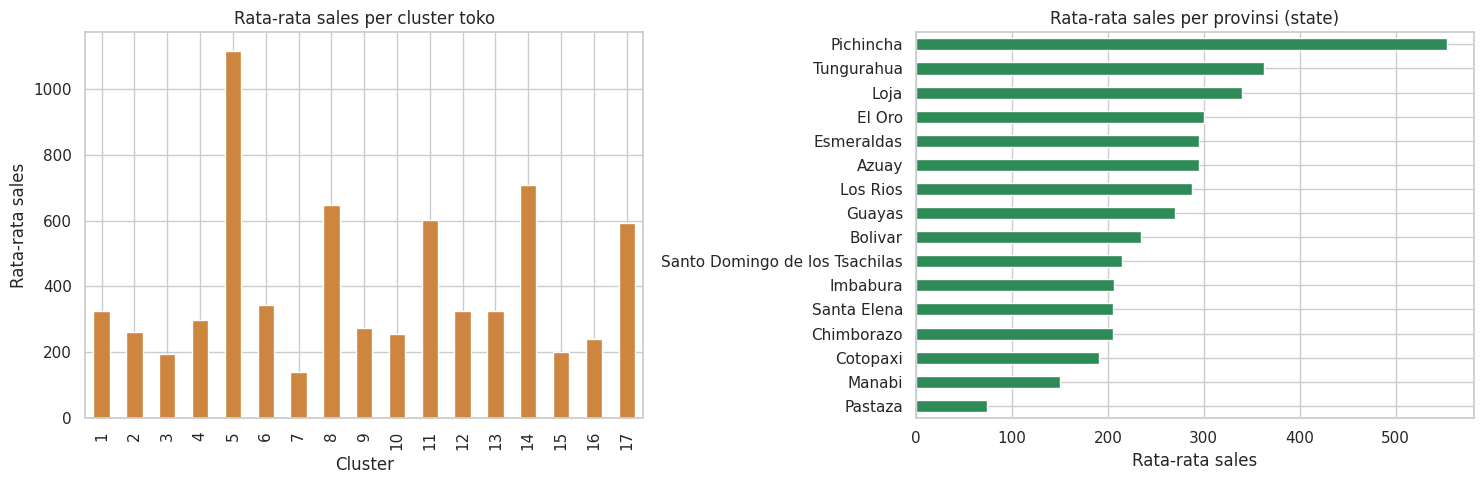

Top-5 kategori menyumbang 78.7% dari total penjualan


In [ ]:
# 3.9 Penjualan per kategori, tipe toko, cluster, dan wilayah
fam_total = train.groupby("family", observed=True)["sales"].sum().sort_values(ascending=False)
rata_toko = train.groupby("store_nbr")["sales"].mean().rename("rata_sales").reset_index().merge(stores, on="store_nbr")

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
(fam_total.head(12) / fam_total.sum() * 100)[::-1].plot.barh(ax=ax[0], color="teal")
ax[0].set_title("Kontribusi 12 kategori teratas terhadap total penjualan (%)")
ax[0].set_xlabel("% dari total sales"); ax[0].set_ylabel("")
sns.barplot(data=rata_toko, x="type", y="rata_sales", order=sorted(rata_toko.type.unique()), ax=ax[1], color="slateblue", errorbar="sd")
ax[1].set_title("Rata-rata sales per baris menurut tipe toko (garis = simpang baku antar toko)")
ax[1].set_xlabel("Tipe toko"); ax[1].set_ylabel("Rata-rata sales per kategori-hari")
simpan_fig("06_family_dan_tipe_toko")

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
rata_toko.groupby("cluster").rata_sales.mean().plot.bar(ax=ax[0], color="peru")
ax[0].set_title("Rata-rata sales per cluster toko"); ax[0].set_xlabel("Cluster"); ax[0].set_ylabel("Rata-rata sales")
rata_toko.groupby("state").rata_sales.mean().sort_values().plot.barh(ax=ax[1], color="seagreen")
ax[1].set_title("Rata-rata sales per provinsi (state)"); ax[1].set_xlabel("Rata-rata sales"); ax[1].set_ylabel("")
simpan_fig("07_cluster_dan_wilayah")
print(f"Top-5 kategori menyumbang {fam_total.head(5).sum()/fam_total.sum():.1%} dari total penjualan")

**Interpretasi.** Penjualan sangat terkonsentrasi pada sedikit kategori (periksa persentase top-5 yang dicetak), dan karakter toko (tipe, cluster, provinsi) berbeda jauh. Konsekuensinya, `family`, `store_nbr`, `tipe_toko`, dan `cluster` layak menjadi fitur, dan evaluasi di Bagian 8 perlu dibedah **per kategori dan per toko**, bukan hanya angka rata-rata.

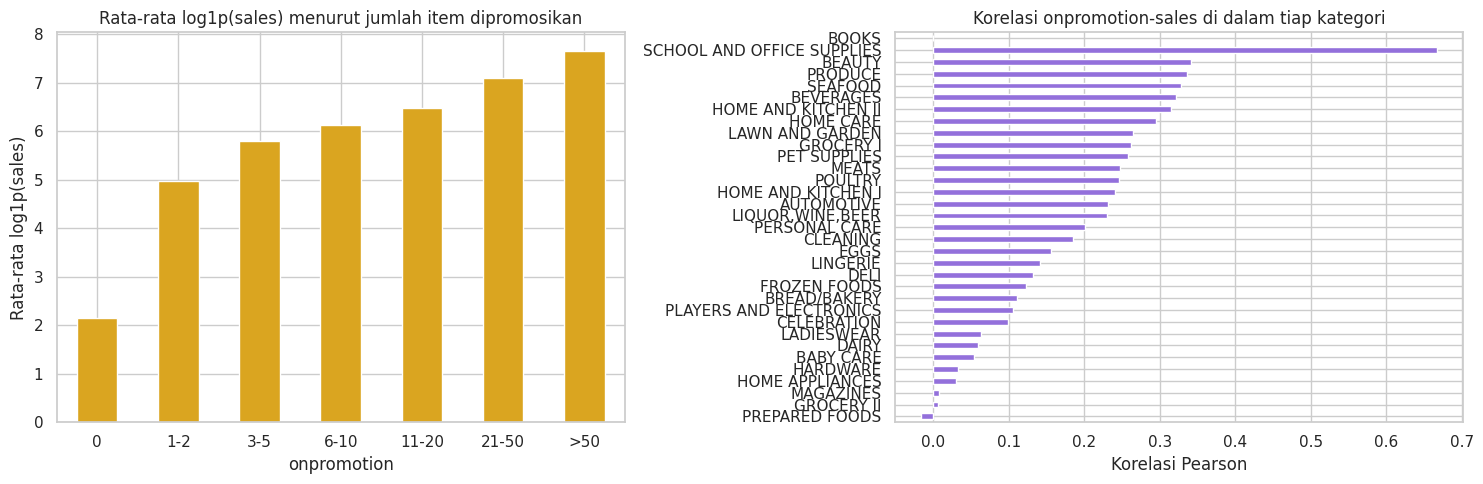

Persentase baris dengan promosi (sejak 2014-04): 27.9%


In [ ]:
# 3.10 Efek promosi (data promosi baru lengkap sejak pertengahan 2014)
t14 = train[train.date >= "2014-04-01"]
bin_promo = pd.cut(t14.onpromotion, bins=[-1, 0, 2, 5, 10, 20, 50, 1e9],
                   labels=["0", "1-2", "3-5", "6-10", "11-20", "21-50", ">50"])
rata_bin = pd.DataFrame({"bin": bin_promo, "ls": np.log1p(t14.sales)}).groupby("bin", observed=True)["ls"].mean()
korelasi_family = t14.groupby("family", observed=True).apply(lambda g: g.onpromotion.corr(g.sales)).sort_values()

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
rata_bin.plot.bar(ax=ax[0], color="goldenrod")
ax[0].set_xticklabels(ax[0].get_xticklabels(), rotation=0)
ax[0].set_title("Rata-rata log1p(sales) menurut jumlah item dipromosikan")
ax[0].set_xlabel("onpromotion"); ax[0].set_ylabel("Rata-rata log1p(sales)")
korelasi_family.plot.barh(ax=ax[1], color="mediumpurple")
ax[1].set_title("Korelasi onpromotion-sales di dalam tiap kategori")
ax[1].set_xlabel("Korelasi Pearson"); ax[1].set_ylabel("")
simpan_fig("08_efek_promosi")
print(f"Persentase baris dengan promosi (sejak 2014-04): {(t14.onpromotion > 0).mean():.1%}")

**Interpretasi.** Grafik kiri bersifat **asosiasi**, bukan sebab-akibat: kategori besar cenderung lebih sering dipromosikan, jadi rata-rata sales yang lebih tinggi pada bin promo besar sebagian mencerminkan *kategori mana* yang dipromosikan. Grafik kanan membandingkan di dalam kategori yang sama, sehingga lebih adil; periksa kategori dengan korelasi tertinggi/terendah. Kami tetap memakai `onpromotion` sebagai fitur karena nilainya **diketahui sebelumnya** (tersedia di `test.csv`).

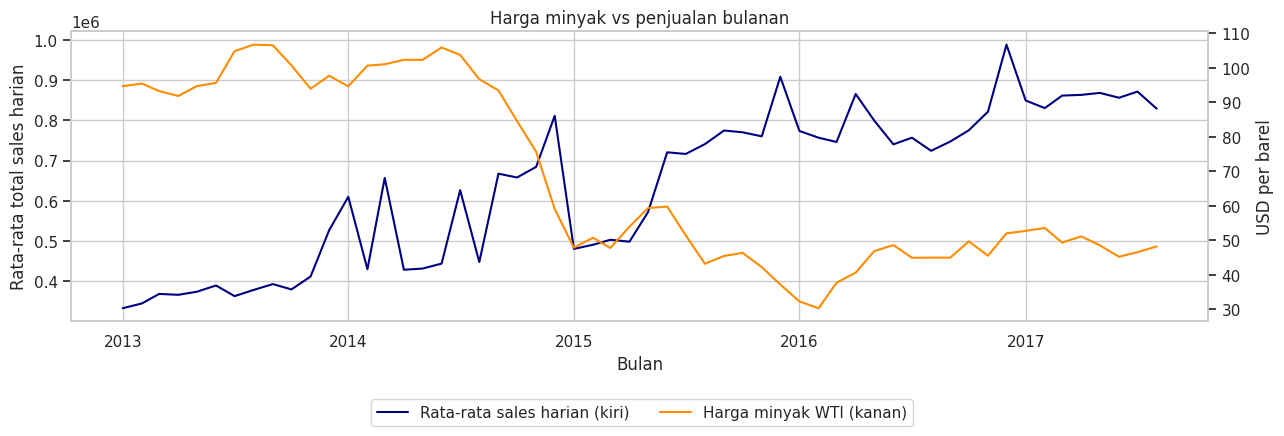

Korelasi level bulanan: -0.79 | korelasi perubahan bulanan: 0.06


In [ ]:
# 3.11 Harga minyak vs penjualan
oil_harian = oil.set_index("date")["dcoilwtico"].reindex(pd.date_range(oil.date.min(), oil.date.max())).ffill().bfill()
bulanan = harian.assign(bulan=harian.date.dt.to_period("M")).groupby("bulan").sales.mean()
oil_bulanan = oil_harian.groupby(oil_harian.index.to_period("M")).mean().reindex(bulanan.index)

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(bulanan.index.to_timestamp(), bulanan.values, color="navy", label="Rata-rata sales harian (kiri)")
ax.set_ylabel("Rata-rata total sales harian"); ax.set_xlabel("Bulan")
ax2 = ax.twinx()
ax2.plot(bulanan.index.to_timestamp(), oil_bulanan.values, color="darkorange", label="Harga minyak WTI (kanan)")
ax2.set_ylabel("USD per barel"); ax2.grid(False)
ax.set_title("Harga minyak vs penjualan bulanan")
fig.legend(loc="upper center", ncol=2, bbox_to_anchor=(0.5, 0.0))
simpan_fig("09_minyak_vs_sales")

r_level = bulanan.corr(oil_bulanan)
r_diff = bulanan.pct_change().corr(oil_bulanan.pct_change())
print(f"Korelasi level bulanan: {r_level:.2f} | korelasi perubahan bulanan: {r_diff:.2f}")

**Interpretasi.** Perhatikan perbedaan antara korelasi **level** dan korelasi **perubahan**. Dua deret yang sama-sama bertren (penjualan naik, minyak turun) bisa tampak berkorelasi kuat padahal hanya kebetulan searah (*spurious correlation*); korelasi perubahan bulanan lebih jujur. Karena itu harga minyak kami masukkan sebagai fitur pendukung (dengan *lag* 16 hari agar valid saat peramalan), dan kami tidak menyimpulkan hubungan sebab-akibat.

,type,locale,transferred,jumlah
0,Additional,Local,False,11
1,Additional,National,False,40
2,Bridge,National,False,5
3,Event,National,False,56
4,Holiday,Local,False,133
5,Holiday,Local,True,4
6,Holiday,National,False,52
7,Holiday,National,True,8
8,Holiday,Regional,False,24
9,Transfer,Local,False,4


Jumlah baris libur setelah dibersihkan: 338 dari 350


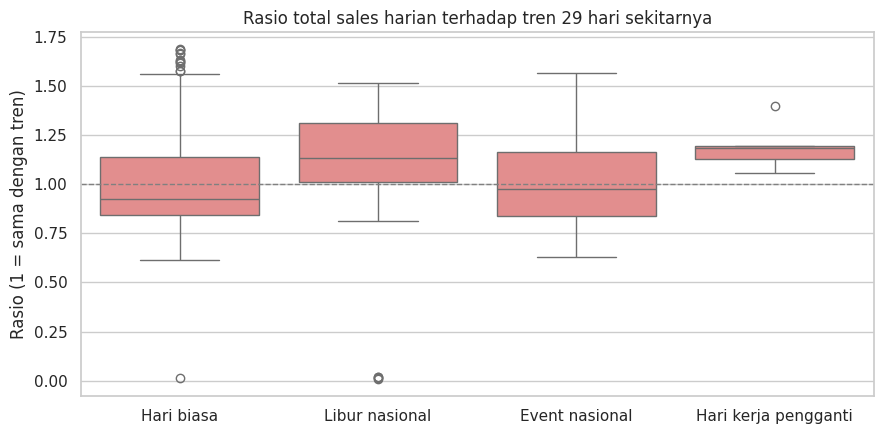

                      count  median
kelompok                           
Event nasional           53   0.976
Hari biasa             1548   0.924
Hari kerja pengganti      5   1.184
Libur nasional           78   1.133


In [ ]:
# 3.12 Hari libur: pembersihan (transferred / Transfer / Bridge / Work Day) dan efeknya
def bersihkan_libur(h):
    """Mengembalikan hari libur/event yang BENAR-BENAR berlaku.
    - Baris dengan transferred=True dibuang (secara resmi dipindah, perilakunya seperti hari biasa).
    - Baris type=Transfer adalah tanggal pelaksanaan sebenarnya -> dihitung sebagai libur.
    - Bridge/Additional dihitung libur; Work Day = hari kerja pengganti; Event = acara (Black Friday, dsb.)."""
    h = h.copy()
    h["date"] = pd.to_datetime(h["date"])
    h = h[~h["transferred"].astype(bool)]
    h["jenis"] = np.select(
        [h["type"].isin(["Holiday", "Transfer", "Additional", "Bridge"]), h["type"].eq("Work Day"), h["type"].eq("Event")],
        ["libur", "hari_kerja_pengganti", "event"], default="lain")
    return h[["date", "type", "locale", "locale_name", "description", "jenis"]]

display(holidays.groupby(["type", "locale", "transferred"]).size().rename("jumlah").reset_index().head(20))
lib = bersihkan_libur(holidays)
print("Jumlah baris libur setelah dibersihkan:", len(lib), "dari", len(holidays))

tgl_libur_nas = pd.DatetimeIndex(lib[(lib.jenis == "libur") & (lib.locale == "National")].date.unique())
tgl_event_nas = pd.DatetimeIndex(lib[(lib.jenis == "event") & (lib.locale == "National")].date.unique())
tgl_workday = pd.DatetimeIndex(lib[lib.jenis == "hari_kerja_pengganti"].date.unique())

hh = harian[harian.sales > 0].copy()
hh["tren"] = hh.sales.rolling(29, center=True, min_periods=15).mean()
hh["rasio"] = hh.sales / hh.tren          # >1 = lebih ramai daripada tren sekitarnya
hh["kelompok"] = "Hari biasa"
hh.loc[hh.date.isin(tgl_event_nas), "kelompok"] = "Event nasional"
hh.loc[hh.date.isin(tgl_workday), "kelompok"] = "Hari kerja pengganti"
hh.loc[hh.date.isin(tgl_libur_nas), "kelompok"] = "Libur nasional"

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.boxplot(data=hh, x="kelompok", y="rasio", ax=ax, order=["Hari biasa", "Libur nasional", "Event nasional", "Hari kerja pengganti"], color="lightcoral")
ax.axhline(1, color="gray", ls="--", lw=1)
ax.set_title("Rasio total sales harian terhadap tren 29 hari sekitarnya")
ax.set_xlabel(""); ax.set_ylabel("Rasio (1 = sama dengan tren)")
simpan_fig("10_efek_libur")
print(hh.groupby("kelompok").rasio.agg(["count", "median"]).round(3))

**Interpretasi.** Memakai kolom `transferred` dengan benar penting: hari yang dipindah (`transferred=True`) **bukan** hari libur sebenarnya, sedangkan baris `Transfer` adalah hari pelaksanaannya. Rasio terhadap tren dipakai agar efek libur tidak tercampur dengan tren jangka panjang. Bandingkan median tiap kelompok pada tabel; kelompok dengan sampel kecil (jumlah hari sedikit) perlu dibaca hati-hati. Pembedaan cakupan *National/Regional/Local* diterapkan di Bagian 4 sesuai lokasi toko.

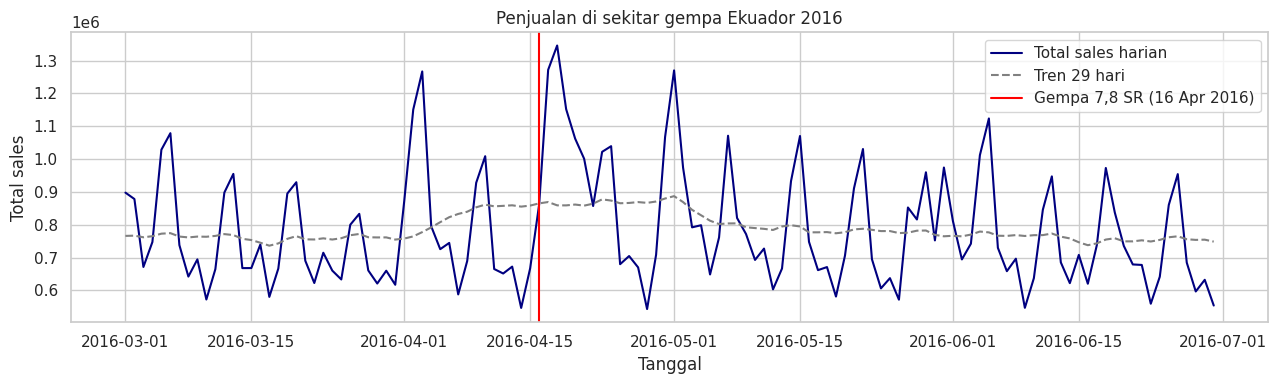

Median rasio terhadap tren, sebelum gempa: 0.902 | 30 hari setelah gempa: 0.994


In [ ]:
# 3.13 Dampak gempa 16 April 2016
GEMPA = pd.Timestamp("2016-04-16")
jendela = hh[(hh.date >= "2016-03-01") & (hh.date <= "2016-06-30")]
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(jendela.date, jendela.sales, color="navy", label="Total sales harian")
ax.plot(jendela.date, jendela.tren, color="gray", ls="--", label="Tren 29 hari")
ax.axvline(GEMPA, color="red", lw=1.5, label="Gempa 7,8 SR (16 Apr 2016)")
ax.set_title("Penjualan di sekitar gempa Ekuador 2016")
ax.set_xlabel("Tanggal"); ax.set_ylabel("Total sales"); ax.legend()
simpan_fig("11_dampak_gempa")

sebelum = jendela[(jendela.date < GEMPA)].rasio.median()
sesudah = jendela[(jendela.date >= GEMPA) & (jendela.date < GEMPA + pd.Timedelta(days=30))].rasio.median()
print(f"Median rasio terhadap tren, sebelum gempa: {sebelum:.3f} | 30 hari setelah gempa: {sesudah:.3f}")

**Interpretasi.** Gempa adalah *kejadian luar biasa* satu kali. Bila grafik/ratio menunjukkan pergeseran setelah 16 April 2016, kami menambahkan penanda `pasca_gempa` (30 hari) agar model tidak mengira lonjakan itu pola musiman biasa. Kami menyadari bahwa penanda ini hanya membantu **belajar dari periode lampau**; model tidak bisa meramalkan kejadian serupa di masa depan.

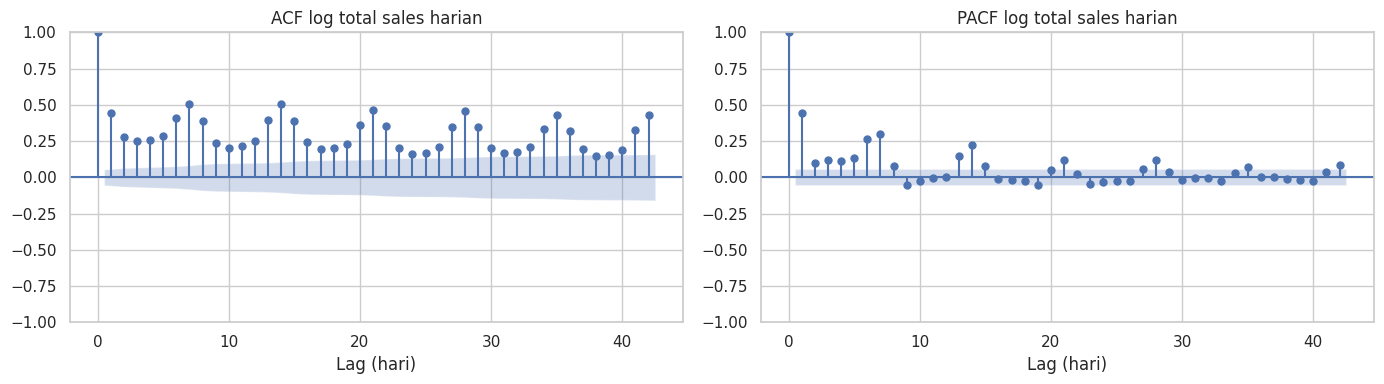

In [ ]:
# 3.14 Autokorelasi total penjualan harian (ketergantungan waktu)
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
seri = np.log1p(harian[(harian.date >= "2014-01-01") & (harian.sales > 0)].set_index("date").sales)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(seri, lags=42, ax=ax[0]); ax[0].set_title("ACF log total sales harian"); ax[0].set_xlabel("Lag (hari)")
plot_pacf(seri, lags=42, ax=ax[1], method="ywm"); ax[1].set_title("PACF log total sales harian"); ax[1].set_xlabel("Lag (hari)")
simpan_fig("12_acf_pacf")

**Interpretasi.** Puncak berulang pada kelipatan 7 hari menunjukkan penjualan hari ini sangat dipengaruhi hari yang sama pada minggu-minggu sebelumnya. Inilah dasar fitur `lag_21`, `lag_28`, `lag_35`, dan rata-rata bergerak. Namun karena kita meramal **15 hari ke depan**, lag yang boleh dipakai minimal 16 hari (lag 7 dan 14 tidak akan diketahui untuk hari ke-8 sampai ke-15 ramalan); alasan ini diuraikan di Bagian 4.

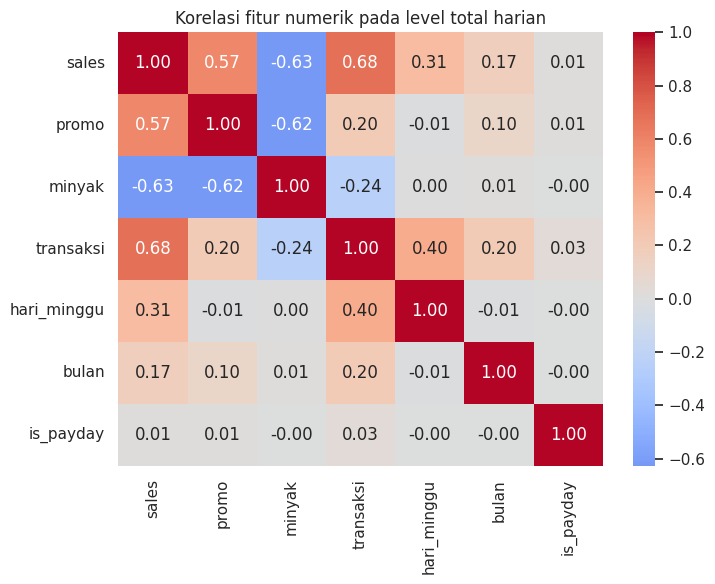

Korelasi sales-transaksi harian: 0.68


In [ ]:
# 3.15 Korelasi antar fitur numerik (level harian)
trx_harian = transactions.groupby("date")["transactions"].sum()
dk = harian.set_index("date").join(oil_harian.rename("minyak"), how="left").join(trx_harian.rename("transaksi"), how="left")
dk["hari_minggu"] = dk.index.dayofweek
dk["bulan"] = dk.index.month
dk["is_payday"] = ((dk.index.day == 15) | dk.index.is_month_end).astype(int)
korelasi = dk[["sales", "promo", "minyak", "transaksi", "hari_minggu", "bulan", "is_payday"]].corr()

fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(korelasi, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Korelasi fitur numerik pada level total harian")
simpan_fig("13_heatmap_korelasi")
print(f"Korelasi sales-transaksi harian: {korelasi.loc['sales','transaksi']:.2f}")

**Interpretasi.** Korelasi `sales`-`transaksi` biasanya sangat tinggi (periksa angkanya), dan inilah jebakan: jumlah transaksi **hari yang sama** tidak diketahui saat meramal masa depan, sehingga memakainya langsung adalah *data leakage*. Heatmap ini bekerja pada level total harian, jadi korelasinya tidak otomatis berlaku pada level toko-kategori; ia dipakai hanya untuk gambaran awal.

### Ringkasan Temuan EDA (rangkuman untuk laporan)
Isi poin-poin berikut berdasarkan output di atas setelah notebook dijalankan: (1) kualitas data (missing, duplikat, tanggal hilang), (2) karakter target (miring, banyak nol), (3) pola mingguan/bulanan/gajian, (4) faktor eksternal (promo, minyak, libur, gempa), (5) implikasi untuk modeling.

## 4. Feature Engineering
*Penanggung jawab: Eka Lidya Rahmadini*

**Tujuan:** mengubah data mentah menjadi fitur yang membantu model meramal 15 hari ke depan, **tanpa kebocoran informasi masa depan**.

**Prinsip utama: horizon 16 hari.** Test berisi 15 hari setelah tanggal terakhir train. Pada hari ke-15 ramalan, penjualan terakhir yang *sudah diketahui* adalah 15 hari sebelumnya, sehingga fitur berbasis penjualan hanya boleh memakai *lag* ≥ 16 hari. Akibatnya, satu model dapat meramal seluruh 15 hari sekaligus (*direct forecasting*) tanpa harus memakai ramalan sebagai input (*recursive*) yang menumpuk error.

**Langkah teknis penting:**
- Kami membangun **kalender lengkap** (setiap hari × setiap toko × setiap family, termasuk 25 Desember yang hilang dan 15 hari test) sehingga `shift(16)` benar-benar berarti 16 *hari*.
- Semua fitur berbasis penjualan dihitung pada `log1p(sales)` dan memakai `shift` ke belakang.
- Fitur eksternal yang tidak diketahui untuk masa depan (harga minyak, transaksi) hanya dipakai dalam bentuk **lag 16 hari**.

In [ ]:
# 4.1 Gabungkan train + test, lalu bangun kalender lengkap (tanggal x toko x family)
tes = test.copy()
tes["sales"] = np.nan
gab = pd.concat([train, tes], ignore_index=True)
gab["family"] = gab["family"].astype(str)
gab["store_nbr"] = gab["store_nbr"].astype("int64")

if SAMPLE_STORES is not None:
    gab = gab[gab.store_nbr.isin(SAMPLE_STORES)]
    print("Subset toko dipakai untuk MODEL:", sorted(SAMPLE_STORES))

TRAIN_END = train.date.max()
TANGGAL = pd.date_range(gab.date.min(), gab.date.max())
TOKO = sorted(gab.store_nbr.unique())
FAMILY = sorted(gab.family.unique())
N_SERIES, T = len(TOKO) * len(FAMILY), len(TANGGAL)

idx = pd.MultiIndex.from_product([TOKO, FAMILY, TANGGAL], names=["store_nbr", "family", "date"])
df = gab.set_index(["store_nbr", "family", "date"]).reindex(idx).reset_index()
df["onpromotion"] = df["onpromotion"].fillna(0)
assert len(df) == N_SERIES * T, "Kalender lengkap harus berisi seluruh kombinasi"
print(f"Kalender lengkap: {len(TOKO)} toko x {len(FAMILY)} family x {T} hari = {len(df):,} baris")
print(f"Baris tanpa sales pada periode train (mis. 25 Des): {int((df.sales.isna() & (df.date <= TRAIN_END)).sum()):,}")
del gab

Kalender lengkap: 54 toko x 33 family x 1704 hari = 3,036,528 baris
Baris tanpa sales pada periode train (mis. 25 Des): 7,128


In [ ]:
# 4.2 Fitur berbasis penjualan masa lalu: lag, rolling, porsi nol
# Data disusun 'series-major' (toko -> family -> tanggal). Kita ubah ke matriks lebar (hari x deret) agar operasi shift/rolling cepat.
Y = pd.DataFrame(np.log1p(df["sales"].values.reshape(N_SERIES, T).T), index=TANGGAL)   # log1p(sales); NaN tetap NaN

def ke_kolom(W):
    """Matriks lebar (hari x deret) -> vektor panjang sesuai urutan baris df."""
    return W.values.T.ravel().astype("float32")

F = {}                                    # penampung fitur baru
for k in [16, 21, 28, 35, 364]:           # semua lag >= 16 hari (horizon peramalan)
    F[f"lag_{k}"] = ke_kolom(Y.shift(k))

S = Y.shift(16)                           # seluruh statistik rolling dihitung dari data yang tersedia 16 hari sebelumnya
for w in [7, 14, 28]:
    F[f"roll_mean_{w}"] = ke_kolom(S.rolling(w, min_periods=max(1, w // 2)).mean())
for w in [7, 28]:
    F[f"roll_std_{w}"] = ke_kolom(S.rolling(w, min_periods=max(2, w // 2)).std())

Z = (Y == 0).astype(float).where(Y.notna())               # 1 jika sales nol, NaN jika tidak ada data
F["zero_share_28"] = ke_kolom(Z.shift(16).rolling(28, min_periods=14).mean())
print("Fitur lag/rolling dibuat:", list(F.keys()))

Fitur lag/rolling dibuat: ['lag_16', 'lag_21', 'lag_28', 'lag_35', 'lag_364', 'roll_mean_7', 'roll_mean_14', 'roll_mean_28', 'roll_std_7', 'roll_std_28', 'zero_share_28']


In [ ]:
# 4.3 Fitur turunan dari lag: rata-rata hari-yang-sama dan momentum
F_lag = pd.DataFrame({k: F[k] for k in ["lag_21", "lag_28", "lag_35"]})
F["dow_mean_3"] = F_lag.mean(axis=1).values.astype("float32")          # rata-rata hari yang sama pada 3, 4, 5 minggu lalu
F["selisih_7_28"] = (F["roll_mean_7"] - F["roll_mean_28"]).astype("float32")  # momentum: apakah 7 hari terakhir di atas rata-rata 28 hari
del Y, S, Z, F_lag

In [ ]:
# 4.4 Fitur kalender, libur, gempa, dan harga minyak (dihitung per tanggal, lalu dipetakan ke seluruh baris)
kal = pd.DataFrame(index=TANGGAL)
kal["bulan"] = TANGGAL.month
kal["hari"] = TANGGAL.day
kal["hari_minggu"] = TANGGAL.dayofweek
kal["minggu_tahun"] = TANGGAL.isocalendar().week.to_numpy().astype(int)
kal["akhir_pekan"] = (TANGGAL.dayofweek >= 5).astype(int)
kal["is_month_start"] = TANGGAL.is_month_start.astype(int)
kal["is_month_end"] = TANGGAL.is_month_end.astype(int)
kal["is_payday"] = ((TANGGAL.day == 15) | TANGGAL.is_month_end).astype(int)   # gaji sektor publik: tgl 15 & akhir bulan
kal["dow_sin"] = np.sin(2 * np.pi * kal.hari_minggu / 7)
kal["dow_cos"] = np.cos(2 * np.pi * kal.hari_minggu / 7)
kal["month_sin"] = np.sin(2 * np.pi * kal.bulan / 12)
kal["month_cos"] = np.cos(2 * np.pi * kal.bulan / 12)

# Libur nasional (memakai fungsi bersihkan_libur dari Bagian 3.12)
lib = bersihkan_libur(holidays)
libur_only = lib[lib.jenis == "libur"]
nat = pd.DatetimeIndex(libur_only[libur_only.locale == "National"].date.unique())
kal["libur_nasional"] = TANGGAL.isin(nat).astype(int)
kal["libur_besok"] = (TANGGAL + pd.Timedelta(days=1)).isin(nat).astype(int)       # efek belanja sebelum libur
kal["libur_kemarin"] = (TANGGAL - pd.Timedelta(days=1)).isin(nat).astype(int)
kal["event_nasional"] = TANGGAL.isin(pd.DatetimeIndex(lib[(lib.jenis == "event") & (lib.locale == "National")].date.unique())).astype(int)
kal["hari_kerja_pengganti"] = TANGGAL.isin(pd.DatetimeIndex(lib[lib.jenis == "hari_kerja_pengganti"].date.unique())).astype(int)
kal["pasca_gempa"] = ((TANGGAL >= GEMPA) & (TANGGAL <= GEMPA + pd.Timedelta(days=30))).astype(int)

# Harga minyak: forward-fill (harga berlaku sampai ada harga baru); hanya dipakai dalam bentuk LAG 16 hari
oil_d = oil.set_index("date")["dcoilwtico"].reindex(TANGGAL).ffill().bfill()
kal["oil_lag16"] = oil_d.shift(16).values
kal["oil_ma7_lag16"] = oil_d.shift(16).rolling(7, min_periods=1).mean().values

pos_d = np.tile(np.arange(T), N_SERIES)           # posisi tanggal tiap baris df
for c in kal.columns:
    F[c] = kal[c].values[pos_d].astype("float32" if kal[c].dtype.kind == "f" else "int8")
print("Fitur kalender/libur/minyak dibuat:", list(kal.columns))

Fitur kalender/libur/minyak dibuat: ['bulan', 'hari', 'hari_minggu', 'minggu_tahun', 'akhir_pekan', 'is_month_start', 'is_month_end', 'is_payday', 'dow_sin', 'dow_cos', 'month_sin', 'month_cos', 'libur_nasional', 'libur_besok', 'libur_kemarin', 'event_nasional', 'hari_kerja_pengganti', 'pasca_gempa', 'oil_lag16', 'oil_ma7_lag16']


In [ ]:
# 4.5 Libur regional & lokal (sesuai provinsi/kota toko), atribut toko, dan transaksi (lag)
toko_info = stores.set_index("store_nbr").loc[TOKO]
reg_mat = np.zeros((len(TOKO), T), dtype=np.int8)
loc_mat = np.zeros((len(TOKO), T), dtype=np.int8)
for i, (sid, r) in enumerate(toko_info.iterrows()):
    reg_mat[i] = TANGGAL.isin(libur_only[(libur_only.locale == "Regional") & (libur_only.locale_name == r["state"])].date)
    loc_mat[i] = TANGGAL.isin(libur_only[(libur_only.locale == "Local") & (libur_only.locale_name == r["city"])].date)
F["libur_regional"] = np.repeat(reg_mat, len(FAMILY), axis=0).ravel()
F["libur_lokal"] = np.repeat(loc_mat, len(FAMILY), axis=0).ravel()

def ekspansi_toko(nilai):
    """Nilai per toko -> per baris df (toko diulang untuk tiap family dan tiap hari)."""
    return np.repeat(np.repeat(np.asarray(nilai), len(FAMILY)), T)

F["tipe_toko"] = ekspansi_toko(toko_info["type"].values)
F["city"] = ekspansi_toko(toko_info["city"].values)
F["state"] = ekspansi_toko(toko_info["state"].values)
F["cluster"] = ekspansi_toko(toko_info["cluster"].values).astype("int16")

# Transaksi: JANGAN pakai transaksi hari yang sama (tidak diketahui saat meramal). Pakai rata-rata 28 hari, digeser 16 hari.
trx_w = transactions.pivot_table(index="date", columns="store_nbr", values="transactions").reindex(index=TANGGAL, columns=TOKO)
trx_roll = trx_w.shift(16).rolling(28, min_periods=7).mean()
F["trans_roll28_lag16"] = np.repeat(trx_roll.values.T, len(FAMILY), axis=0).ravel().astype("float32")
print("Fitur toko, libur regional/lokal, dan transaksi (lag) dibuat.")

Fitur toko, libur regional/lokal, dan transaksi (lag) dibuat.


In [ ]:
# 4.6 Gabungkan semua fitur, bentuk dataset model
df = pd.concat([df, pd.DataFrame(F, index=df.index)], axis=1)
del F
df["y"] = np.log1p(df["sales"]).astype("float32")
df["is_test"] = df["date"] > TRAIN_END
for c in ["store_nbr", "family", "tipe_toko", "city", "state"]:
    df[c] = df[c].astype("category")

# Hanya baris yang punya target (train) atau baris test; mulai dari START_DATE
df_model = df[(df["date"] >= START_DATE) & (df["is_test"] | df["sales"].notna())].copy()
df_model = df_model.sort_values(["date", "store_nbr", "family"]).reset_index(drop=True)   # urut waktu (wajib untuk TimeSeriesSplit)
del df

FITUR_NUM = ["onpromotion", "cluster",
             "lag_16", "lag_21", "lag_28", "lag_35", "lag_364",
             "roll_mean_7", "roll_mean_14", "roll_mean_28", "roll_std_7", "roll_std_28",
             "zero_share_28", "dow_mean_3", "selisih_7_28", "trans_roll28_lag16",
             "oil_lag16", "oil_ma7_lag16",
             "bulan", "hari", "hari_minggu", "minggu_tahun", "akhir_pekan",
             "is_payday", "is_month_start", "is_month_end",
             "dow_sin", "dow_cos", "month_sin", "month_cos",
             "libur_nasional", "libur_regional", "libur_lokal", "libur_besok", "libur_kemarin",
             "event_nasional", "hari_kerja_pengganti", "pasca_gempa"]
FITUR_CAT = ["store_nbr", "family", "tipe_toko", "city", "state"]
FITUR = FITUR_NUM + FITUR_CAT

print("Ukuran dataset model:", df_model.shape, "| memori ~", round(df_model.memory_usage(deep=True).sum() / 1e6), "MB")
print("Jumlah fitur:", len(FITUR), f"({len(FITUR_NUM)} numerik + {len(FITUR_CAT)} kategorikal)")
print("Missing value pada fitur (persen) - hanya yang > 0:")
display((df_model[FITUR].isna().mean() * 100).round(2).loc[lambda s: s > 0].to_frame("persen_missing"))

Ukuran dataset model: (1732104, 48) | memori ~ 236 MB
Jumlah fitur: 43 (38 numerik + 5 kategorikal)
Missing value pada fitur (persen) - hanya yang > 0:


,persen_missing
lag_16,0.31
lag_21,0.31
lag_28,0.31
lag_35,0.31
lag_364,0.21
trans_roll28_lag16,3.81


In [ ]:
# 4.7 Kamus fitur: alasan bisnis tiap fitur
KAMUS_FITUR = {
    "onpromotion": "Jumlah item yang sedang dipromosikan; promo mendorong pembelian (nilainya diketahui lebih dulu).",
    "cluster": "Kelompok toko dengan karakter serupa.",
    "lag_16": "Penjualan 16 hari lalu: lag terdekat yang tersedia saat meramal 15 hari ke depan.",
    "lag_21": "Penjualan pada hari yang sama 3 minggu lalu (pola mingguan).",
    "lag_28": "Penjualan pada hari yang sama 4 minggu lalu (pola mingguan/bulanan).",
    "lag_35": "Penjualan pada hari yang sama 5 minggu lalu.",
    "lag_364": "Penjualan pada hari yang sama tahun lalu (musiman tahunan).",
    "roll_mean_7": "Rata-rata level penjualan terbaru (7 hari, tergeser 16 hari).",
    "roll_mean_14": "Rata-rata level penjualan 14 hari (tergeser 16 hari).",
    "roll_mean_28": "Rata-rata level penjualan 28 hari: level dasar permintaan.",
    "roll_std_7": "Volatilitas penjualan jangka pendek.",
    "roll_std_28": "Volatilitas penjualan 28 hari.",
    "zero_share_28": "Porsi hari tanpa penjualan: membedakan produk mati vs produk laku.",
    "dow_mean_3": "Rata-rata hari-yang-sama dari 3 minggu terpisah (menghaluskan noise).",
    "selisih_7_28": "Momentum: apakah penjualan terbaru naik/turun dibanding level 28 hari.",
    "trans_roll28_lag16": "Rata-rata transaksi toko (28 hari, tergeser 16): ukuran keramaian toko tanpa leakage.",
    "oil_lag16": "Harga minyak 16 hari lalu: proksi kondisi ekonomi Ekuador.",
    "oil_ma7_lag16": "Rata-rata 7 hari harga minyak (tergeser 16 hari).",
    "bulan": "Musiman bulanan.", "hari": "Tanggal dalam bulan.", "hari_minggu": "Hari dalam seminggu.",
    "minggu_tahun": "Minggu ke-n dalam tahun.", "akhir_pekan": "Sabtu/Minggu.",
    "is_payday": "Tanggal gajian sektor publik (15 dan akhir bulan).",
    "is_month_start": "Awal bulan.", "is_month_end": "Akhir bulan.",
    "dow_sin": "Hari-dalam-minggu sebagai sinyal siklik (sin).", "dow_cos": "Hari-dalam-minggu (cos).",
    "month_sin": "Bulan sebagai sinyal siklik (sin).", "month_cos": "Bulan (cos).",
    "libur_nasional": "Hari libur nasional yang berlaku sebenarnya.",
    "libur_regional": "Libur di provinsi tempat toko berada.", "libur_lokal": "Libur di kota tempat toko berada.",
    "libur_besok": "Besok libur nasional: orang berbelanja lebih dulu.", "libur_kemarin": "Kemarin libur nasional.",
    "event_nasional": "Event nasional (Black Friday, Hari Ibu, dll.).",
    "hari_kerja_pengganti": "Hari kerja pengganti (Work Day).",
    "pasca_gempa": "30 hari setelah gempa 16 April 2016.",
    "store_nbr": "Identitas toko.", "family": "Kategori produk.", "tipe_toko": "Tipe toko (A-E).",
    "city": "Kota toko.", "state": "Provinsi toko.",
}
tabel_kamus = pd.DataFrame({"fitur": FITUR, "alasan_bisnis": [KAMUS_FITUR.get(f, "-") for f in FITUR]})
display(tabel_kamus)

,fitur,alasan_bisnis
0,onpromotion,Jumlah item yang sedang dipromosikan; promo me...
1,cluster,Kelompok toko dengan karakter serupa.
2,lag_16,Penjualan 16 hari lalu: lag terdekat yang ters...
3,lag_21,Penjualan pada hari yang sama 3 minggu lalu (p...
4,lag_28,Penjualan pada hari yang sama 4 minggu lalu (p...
5,lag_35,Penjualan pada hari yang sama 5 minggu lalu.
6,lag_364,Penjualan pada hari yang sama tahun lalu (musi...
7,roll_mean_7,"Rata-rata level penjualan terbaru (7 hari, ter..."
8,roll_mean_14,Rata-rata level penjualan 14 hari (tergeser 16...
9,roll_mean_28,Rata-rata level penjualan 28 hari: level dasar...


### Interpretasi Bagian 4 & keputusan penting
- **Tidak ada kebocoran waktu:** semua fitur berbasis penjualan dan minyak/transaksi memakai `shift(≥16)`. Karena jarak minimal 16 hari melebihi horizon 15 hari, fitur untuk setiap hari test dapat dihitung dari data yang sudah diketahui.
- **`transactions.csv`:** nilai transaksi hari yang sama sangat berkorelasi dengan `sales` (lihat 3.15) tetapi **tidak tersedia saat meramal**. Keputusan kami: hanya dipakai sebagai rata-rata 28 hari yang digeser 16 hari (`trans_roll28_lag16`).
- **Harga minyak** juga dipakai dalam bentuk *lag* 16 hari karena harga masa depan tidak diketahui.
- Missing value pada fitur *lag* di awal deret tidak dibuang; ditangani oleh model (LightGBM) atau imputasi pada pipeline (Bagian 5).
- Kolom `tahun` sengaja **tidak** dipakai: tren jangka panjang ditangkap lewat *lag*/*rolling*, dan pohon keputusan tidak bisa meng-ekstrapolasi tahun yang belum pernah dilihat.

## 5. Preprocessing & Split Berbasis Waktu
*Penanggung jawab: Dwi Aura Ningrum*

**Mengapa tidak boleh *random split*?** Pada deret waktu, baris acak membuat model "mengintip" hari-hari setelah hari yang diuji (data tetangga yang sangat mirip), sehingga skor tampak bagus tetapi tidak mencerminkan kondisi nyata, yaitu meramal masa depan. Kami memakai **split kronologis**:

- **Train:** seluruh data sampai `VAL_START - 1 hari`.
- **Validasi (test internal):** `VAL_DAYS` hari terakhir sebelum akhir train (default 15 hari, **sama dengan horizon test sebenarnya**). Karena semua fitur memakai lag ≥ 16 hari, fitur validasi hanya memakai data yang sudah ada di periode train, persis seperti kondisi saat meramal test.
- **Cross-validation:** `TimeSeriesSplit` (*expanding window*) dengan jeda (*gap*) 16 hari antara train dan fold uji, bukan `KFold` acak.

In [ ]:
# 5.1 Split kronologis
VAL_START = TRAIN_END - pd.Timedelta(days=VAL_DAYS - 1)
tr_mask = (~df_model.is_test) & (df_model.date < VAL_START)
va_mask = (~df_model.is_test) & (df_model.date >= VAL_START)

X_train, y_train = df_model.loc[tr_mask, FITUR], df_model.loc[tr_mask, "y"]
X_val, y_val = df_model.loc[va_mask, FITUR], df_model.loc[va_mask, "y"]

# Cek anti-leakage: fitur terbaru pada validasi memakai data paling awal (tanggal - 16 hari); harus sudah ada di periode train
tgl_train_akhir = df_model.loc[tr_mask, "date"].max()
tgl_data_terakhir_dipakai = df_model.loc[va_mask, "date"].max() - pd.Timedelta(days=16)
assert tgl_data_terakhir_dipakai <= tgl_train_akhir, "VAL_DAYS terlalu besar: fitur validasi memakai data periode validasi (leakage)"

ringkas_split = pd.DataFrame({
    "bagian": ["Train", "Validasi"],
    "mulai": [df_model.loc[tr_mask, "date"].min().date(), df_model.loc[va_mask, "date"].min().date()],
    "selesai": [tgl_train_akhir.date(), df_model.loc[va_mask, "date"].max().date()],
    "jumlah_baris": [tr_mask.sum(), va_mask.sum()]})
display(ringkas_split)
print("Cek anti-leakage lulus: data paling baru yang dipakai fitur validasi =", tgl_data_terakhir_dipakai.date(),
      "<= akhir train =", tgl_train_akhir.date())

N_SERIES_AKTIF = len(TOKO) * len(FAMILY)
hari_train = (tgl_train_akhir - df_model.loc[tr_mask, "date"].min()).days + 1
hari_minimal = N_CV_SPLITS * 15 + 16 + 60
assert hari_train >= hari_minimal, (f"Periode train hanya {hari_train} hari; butuh minimal {hari_minimal} hari untuk CV berbasis waktu. "
                                    f"Majukan START_DATE ke tanggal yang lebih awal.")

def buat_tscv(n_splits=N_CV_SPLITS):
    """TimeSeriesSplit expanding window: fold uji 15 hari, jeda 16 hari antara train dan uji (data sudah urut tanggal)."""
    return TimeSeriesSplit(n_splits=n_splits, test_size=15 * N_SERIES_AKTIF, gap=16 * N_SERIES_AKTIF)

,bagian,mulai,selesai,jumlah_baris
0,Train,2015-01-01,2017-07-31,1676862
1,Validasi,2017-08-01,2017-08-15,26730


Cek anti-leakage lulus: data paling baru yang dipakai fitur validasi = 2017-07-30 <= akhir train = 2017-07-31


In [ ]:
# 5.2 Pipeline preprocessing (semua transformer di-fit HANYA pada data train)
def pre_ridge():
    """Ridge butuh data numerik tanpa NaN dan skala seragam + one-hot untuk kategorikal."""
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), FITUR_NUM),
        ("cat", OneHotEncoder(handle_unknown="ignore"), FITUR_CAT)])

def pre_rf():
    """Random Forest tidak butuh scaling; kategorikal di-ordinal-encode, NaN diimputasi median."""
    return ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), FITUR_NUM),
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), FITUR_CAT)])

# LightGBM: memakai kolom 'category' secara native dan menangani NaN sendiri, jadi tanpa transformer tambahan.
print("Pipeline siap. Ringkasan penanganan per model:")
display(pd.DataFrame({
    "model": ["Ridge", "Random Forest", "LightGBM"],
    "imputasi NaN": ["median (fit di train)", "median (fit di train)", "native (NaN dikelola pohon)"],
    "encoding kategorikal": ["One-Hot", "Ordinal", "native categorical"],
    "scaling": ["StandardScaler", "tidak perlu", "tidak perlu"]}))

Pipeline siap. Ringkasan penanganan per model:


,model,imputasi NaN,encoding kategorikal,scaling
0,Ridge,median (fit di train),One-Hot,StandardScaler
1,Random Forest,median (fit di train),Ordinal,tidak perlu
2,LightGBM,native (NaN dikelola pohon),native categorical,tidak perlu


### Interpretasi Bagian 5
- Periksa tabel split: validasi adalah periode paling akhir dan **tidak pernah dilihat** saat training; cek anti-leakage memastikan fitur validasi hanya memakai informasi dari periode train.
- Target dilatih dalam bentuk `log1p(sales)`. Saat evaluasi, prediksi dikembalikan dengan `expm1` dan dipotong minimal 0 (penjualan tidak boleh negatif).
- Validasi hanya 15 hari, sehingga satu angka validasi bisa tidak stabil. Karena itu kami melengkapinya dengan *cross-validation* berbasis waktu (Bagian 7.5) dan membaca hasil keduanya bersama-sama.

## 6. Pemilihan Algoritma
*Penanggung jawab: Anavalis Ridho Abdee Nugroho*

Kami membandingkan satu pembanding sederhana (baseline naif) dan tiga algoritma regresi yang mewakili tiga keluarga berbeda. Pemilihan didasarkan pada karakter data: panel deret waktu (1.782 deret pada data penuh), target miring, banyak fitur numerik dan kategorikal, serta interaksi nonlinier (mis. promo × kategori × hari libur).

| Model | Keluarga | Alasan dipilih | Kelebihan | Kekurangan |
|---|---|---|---|---|
| **Baseline naif** (`lag_21`, rata-rata 28 hari) | Aturan sederhana | Pembanding wajib: model yang rumit harus mengalahkan tebakan sederhana | Tanpa training, sangat mudah dijelaskan | Tidak menangkap promo, libur, atau tren |
| **Ridge Regression** | Linear terregularisasi | Baseline terukur dan *interpretable*; koefisien bisa dibaca | Cepat, stabil, tahan multikolinearitas (banyak lag yang saling berkorelasi) | Hanya hubungan linear; interaksi harus dibuat manual |
| **Random Forest** | Ensemble pohon (*bagging*) | Menangkap nonlinier dan interaksi tanpa banyak tuning | Tahan outlier, tidak perlu scaling | Lambat dan berat memori pada jutaan baris; tidak meng-ekstrapolasi |
| **LightGBM** | Gradient boosting | Umumnya terbaik untuk data tabular berfitur *lag* dan kategorikal banyak | Cepat, native kategorikal dan NaN, akurat | Banyak hyperparameter; berisiko *overfit* bila tidak dikontrol |

**Metrik utama RMSLE** dipilih karena target miring dan bisnis lebih peduli selisih relatif daripada selisih absolut pada kategori bervolume besar. Metrik pendukung: RMSE, MAE, R², WAPE.

## 7. Modeling, Cross-Validation & Tuning

### 7.1 Fungsi evaluasi & baseline naif
*Penanggung jawab: Hany Nadya Fairuz*

In [ ]:
# 7.1 Fungsi metrik dan model baseline naif
def metrik(y_log_true, pred_log):
    """Hitung metrik pada skala asli. Input berupa log1p(sales); prediksi dipotong minimal 0."""
    pred_log = np.clip(np.asarray(pred_log, dtype="float64"), 0, None)
    y_log_true = np.asarray(y_log_true, dtype="float64")
    y, p = np.expm1(y_log_true), np.expm1(pred_log)
    return {"RMSLE": float(np.sqrt(mean_squared_error(y_log_true, pred_log))),
            "RMSE": float(np.sqrt(mean_squared_error(y, p))),
            "MAE": float(mean_absolute_error(y, p)),
            "R2": float(r2_score(y, p)),
            "WAPE": float(np.abs(y - p).sum() / max(y.sum(), 1e-9))}

HASIL, PRED_VAL, MODEL = [], {}, {}

def catat(nama, pred_val, waktu=0.0, metrik_train=None):
    m = metrik(y_val, pred_val)
    PRED_VAL[nama] = np.clip(np.asarray(pred_val, dtype="float64"), 0, None)
    baris = {"model": nama, **{f"{k}": v for k, v in m.items()}, "waktu_train_detik": round(waktu, 1)}
    if metrik_train is not None:
        baris["RMSLE_train"] = metrik_train["RMSLE"]
    HASIL.append(baris)
    return m

# Baseline 1: seasonal naive (hari yang sama 3 minggu lalu; lag 7 tidak boleh dipakai karena horizon 15 hari)
b1 = X_val["lag_21"].fillna(X_val["roll_mean_28"]).fillna(0)
# Baseline 2: rata-rata 28 hari terakhir (tergeser 16 hari)
b2 = X_val["roll_mean_28"].fillna(0)
m1 = catat("Baseline: Seasonal Naive (lag_21)", b1)
m2 = catat("Baseline: Rata-rata 28 hari", b2)
display(pd.DataFrame([m1, m2], index=["Seasonal Naive (lag_21)", "Rata-rata 28 hari"]).round(4))

,RMSLE,RMSE,MAE,R2,WAPE
Seasonal Naive (lag_21),0.6371,334.5431,93.3169,0.9277,0.2006
Rata-rata 28 hari,0.5536,323.1779,96.7419,0.9325,0.2080


**Interpretasi.** Angka baseline ini adalah **lantai** yang harus dikalahkan model. Seasonal naive menyalin hari yang sama 3 minggu lalu (menangkap pola mingguan), sedangkan rata-rata 28 hari hanya menangkap level. Sebuah model yang tidak lebih baik dari keduanya tidak layak dipakai walaupun rumit.

In [ ]:
# Fungsi bantu training generik (dipakai semua model di 7.2 - 7.4)
def sampel_baris(X, y, max_rows):
    """Ambil sampel baris acak (urutan waktu dipertahankan). Dipakai agar model berat tetap cepat."""
    if max_rows is None or len(X) <= max_rows:
        return X, y
    idx = np.sort(np.random.RandomState(SEED).choice(len(X), max_rows, replace=False))
    return X.iloc[idx], y.iloc[idx]

def latih_dan_catat(nama, model, max_rows=None):
    Xt, yt = sampel_baris(X_train, y_train, max_rows)
    t0 = time.time()
    model.fit(Xt, yt)
    waktu = time.time() - t0
    pred_val = model.predict(X_val)
    Xs, ys = sampel_baris(Xt, yt, 200_000)                  # skor train (sampel) untuk cek overfitting
    m_train = metrik(ys, model.predict(Xs))
    m = catat(nama, pred_val, waktu, m_train)
    MODEL[nama] = model
    print(f"{nama}: RMSLE validasi = {m['RMSLE']:.4f} | RMSLE train = {m_train['RMSLE']:.4f} | waktu = {waktu:.1f} dtk")
    return model

### 7.2 Ridge Regression
*Penanggung jawab: Anavalis Ridho Abdee Nugroho*

In [ ]:
def buat_ridge(alpha=1.0):
    return Pipeline([("pre", pre_ridge()), ("model", Ridge(alpha=alpha, random_state=SEED))])

latih_dan_catat("Ridge", buat_ridge())

Ridge: RMSLE validasi = 0.5443 | RMSLE train = 0.6504 | waktu = 19.1 dtk


Pipeline(steps=[('pre',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imp',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('sc',
                                                                   StandardScaler())]),
                                                  ['onpromotion', 'cluster',
                                                   'lag_16', 'lag_21', 'lag_28',
                                                   'lag_35', 'lag_364',
                                                   'roll_mean_7',
                                                   'roll_mean_14',
                                                   'roll_mean_28', 'roll_std_7',
                                                   'roll_std_28',
                                                   'zero_share_28',
                                                   'dow_mean_3', 'selisih_7_28',
                                                   'trans_roll28_lag16',
                                                   'oil_lag16', 'oil_ma7_lag16',
                                                   'bulan', 'hari',
                                                   'hari_minggu',
                                                   'minggu_tahun',
                                                   'akhir_pekan', 'is_payday',
                                                   'is_month_start',
                                                   'is_month_end', 'dow_sin',
                                                   'dow_cos', 'month_sin',
                                                   'month_cos', ...]),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['store_nbr', 'family',
                                                   'tipe_toko', 'city',
                                                   'state'])])),
                ('model', Ridge(random_state=42))])

### 7.3 Random Forest
*Penanggung jawab: Hany Nadya Fairuz*

Random Forest dilatih pada **sampel baris acak** dari data train (`RF_MAX_ROWS`). Ini hanya mengurangi jumlah contoh latih; fitur *lag* sudah dibangun sebelum split sehingga tidak ada kebocoran. Konsekuensinya RF mungkin sedikit tidak diuntungkan dibanding model lain yang memakai seluruh data, dan hal ini perlu disebut saat membandingkan.

In [ ]:
def buat_rf(**kw):
    param = dict(n_estimators=80, max_depth=14, min_samples_leaf=20, max_features=0.5, n_jobs=-1, random_state=SEED)
    param.update(kw)
    return Pipeline([("pre", pre_rf()), ("model", RandomForestRegressor(**param))])

latih_dan_catat("Random Forest", buat_rf(), max_rows=RF_MAX_ROWS)

Random Forest: RMSLE validasi = 0.4616 | RMSLE train = 0.5088 | waktu = 124.0 dtk


Pipeline(steps=[('pre',
                 ColumnTransformer(transformers=[('num',
                                                  SimpleImputer(strategy='median'),
                                                  ['onpromotion', 'cluster',
                                                   'lag_16', 'lag_21', 'lag_28',
                                                   'lag_35', 'lag_364',
                                                   'roll_mean_7',
                                                   'roll_mean_14',
                                                   'roll_mean_28', 'roll_std_7',
                                                   'roll_std_28',
                                                   'zero_share_28',
                                                   'dow_mean_3', 'selisih_7_28',
                                                   'trans_roll28_lag16',
                                                   'oil_lag16', 'oil_ma7_lag16',
                                                   'bulan', 'hari',
                                                   'hari...
                                                   'akhir_pekan', 'is_payday',
                                                   'is_month_start',
                                                   'is_month_end', 'dow_sin',
                                                   'dow_cos', 'month_sin',
                                                   'month_cos', ...]),
                                                 ('cat',
                                                  OrdinalEncoder(handle_unknown='use_encoded_value',
                                                                 unknown_value=-1),
                                                  ['store_nbr', 'family',
                                                   'tipe_toko', 'city',
                                                   'state'])])),
                ('model',
                 RandomForestRegressor(max_depth=14, max_features=0.5,
                                       min_samples_leaf=20, n_estimators=80,
                                       n_jobs=-1, random_state=42))])

### 7.4 LightGBM
*Penanggung jawab: Anavalis Ridho Abdee Nugroho*

In [ ]:
def buat_lgbm(**kw):
    param = dict(n_estimators=500, learning_rate=0.05, num_leaves=63, min_child_samples=50,
                 subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
                 importance_type="gain", random_state=SEED, n_jobs=-1, verbose=-1)
    param.update(kw)
    return lgb.LGBMRegressor(**param)

latih_dan_catat("LightGBM", buat_lgbm())

LightGBM: RMSLE validasi = 0.4105 | RMSLE train = 0.3969 | waktu = 98.5 dtk


LGBMRegressor(colsample_bytree=0.8, importance_type='gain', learning_rate=0.05,
              min_child_samples=50, n_estimators=500, n_jobs=-1, num_leaves=63,
              random_state=42, reg_lambda=1.0, subsample=0.8, subsample_freq=1,
              verbose=-1)

### 7.5 Cross-Validation berbasis waktu
*Penanggung jawab: Hany Nadya Fairuz*

`TimeSeriesSplit` dengan jendela *expanding*: setiap lipatan melatih pada masa lalu dan menguji pada 15 hari berikutnya setelah jeda 16 hari. Ini memberi gambaran kestabilan model lintas periode (bukan hanya 15 hari terakhir).

In [ ]:
FABRIK = {"Ridge": (buat_ridge, None), "Random Forest": (buat_rf, RF_MAX_ROWS), "LightGBM": (buat_lgbm, None)}
CV_HASIL = {}

def cv_rmsle(fabrik, max_rows=None):
    skor = []
    for tr_idx, te_idx in buat_tscv().split(X_train):
        Xt, yt = sampel_baris(X_train.iloc[tr_idx], y_train.iloc[tr_idx], max_rows)
        m = fabrik()
        m.fit(Xt, yt)
        skor.append(metrik(y_train.iloc[te_idx], m.predict(X_train.iloc[te_idx]))["RMSLE"])
    return skor

for nama, (fab, mr) in FABRIK.items():
    t0 = time.time()
    CV_HASIL[nama] = cv_rmsle(fab, mr)
    print(f"{nama}: RMSLE per fold = {np.round(CV_HASIL[nama], 4)} | rata-rata = {np.mean(CV_HASIL[nama]):.4f} "
          f"± {np.std(CV_HASIL[nama]):.4f} | {time.time()-t0:.0f} dtk")

tabel_cv = pd.DataFrame({n: {"CV_RMSLE_mean": np.mean(s), "CV_RMSLE_std": np.std(s)} for n, s in CV_HASIL.items()}).T
display(tabel_cv.round(4))

Ridge: RMSLE per fold = [0.4408 0.4228 0.4489] | rata-rata = 0.4375 ± 0.0109 | 58 dtk
Random Forest: RMSLE per fold = [0.4028 0.3866 0.412 ] | rata-rata = 0.4005 ± 0.0105 | 297 dtk
LightGBM: RMSLE per fold = [0.3883 0.3795 0.4072] | rata-rata = 0.3917 ± 0.0116 | 263 dtk


,CV_RMSLE_mean,CV_RMSLE_std
Ridge,0.4375,0.0109
Random Forest,0.4005,0.0105
LightGBM,0.3917,0.0116


**Interpretasi.** Perhatikan dua hal: (1) **rata-rata** CV: model mana yang konsisten terbaik; (2) **simpangan baku**: model dengan simpangan besar berarti performanya bergantung pada periode (mis. fold yang memuat libur panjang). Bila urutan model pada CV berbeda dari urutan pada validasi 15 hari, validasi tunggal kemungkinan dipengaruhi kondisi periode tersebut dan sebaiknya tidak dipakai sendirian.

### 7.6 Hyperparameter Tuning (LightGBM)
*Penanggung jawab: Anavalis Ridho Abdee Nugroho*

Tuning ringan dengan `RandomizedSearchCV` memakai `TimeSeriesSplit` (bukan KFold acak) pada **`TUNE_ROWS` baris terbaru** agar waktu eksekusi wajar. Skor yang dioptimalkan adalah RMSLE (RMSE pada target `log1p` dengan prediksi dipotong ≥ 0).

In [ ]:
def skor_rmsle(y_true, y_pred):
    return -float(np.sqrt(np.mean((np.clip(y_pred, 0, None) - y_true) ** 2)))

# Jumlah baris minimum agar TimeSeriesSplit (fold uji 15 hari + jeda 16 hari) tetap valid, apa pun nilai TUNE_ROWS
n_min_tune = (N_CV_SPLITS * 15 + 16 + 30) * N_SERIES_AKTIF
n_tune = min(len(X_train), max(TUNE_ROWS, n_min_tune))
if n_tune > TUNE_ROWS:
    print(f"TUNE_ROWS dinaikkan otomatis dari {TUNE_ROWS:,} ke {n_tune:,} agar cross-validation berbasis waktu valid.")
X_tune, y_tune = X_train.iloc[-n_tune:], y_train.iloc[-n_tune:]

ruang_cari = {
    "num_leaves": [31, 63, 127],
    "learning_rate": [0.03, 0.05, 0.08],
    "n_estimators": [300, 500, 700],
    "min_child_samples": [20, 50, 100],
    "colsample_bytree": [0.6, 0.8, 1.0],
    "reg_lambda": [0.0, 1.0, 5.0],
}
t0 = time.time()
pencarian = RandomizedSearchCV(buat_lgbm(), ruang_cari, n_iter=N_ITER_TUNING, cv=buat_tscv(),
                               scoring=make_scorer(skor_rmsle), random_state=SEED, n_jobs=1, refit=False, verbose=1)
pencarian.fit(X_tune, y_tune)
print(f"Tuning selesai dalam {time.time()-t0:.0f} dtk")
print("Parameter terbaik:", pencarian.best_params_)
print(f"CV RMSLE terbaik (pada {n_tune:,} baris terbaru): {-pencarian.best_score_:.4f}")

cv_tuning = pd.DataFrame(pencarian.cv_results_)[["params", "mean_test_score"]].assign(
    RMSLE=lambda d: -d.mean_test_score).sort_values("RMSLE")[["RMSLE", "params"]]
display(cv_tuning.head(5))

BEST_LGBM_PARAMS = pencarian.best_params_
FABRIK["LightGBM (tuned)"] = (lambda: buat_lgbm(**BEST_LGBM_PARAMS), None)
CV_HASIL["LightGBM (tuned)"] = [-pencarian.best_score_]       # skor CV tuning (pada subset terbaru; lihat catatan di Bagian 9)
latih_dan_catat("LightGBM (tuned)", buat_lgbm(**BEST_LGBM_PARAMS))

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Tuning selesai dalam 431 dtk
Parameter terbaik: {'reg_lambda': 5.0, 'num_leaves': 63, 'n_estimators': 700, 'min_child_samples': 20, 'learning_rate': 0.03, 'colsample_bytree': 0.8}
CV RMSLE terbaik (pada 400,000 baris terbaru): 0.3952


,RMSLE,params
5,0.395210,"{'reg_lambda': 5.0, 'num_leaves': 63, 'n_estim..."
2,0.396079,"{'reg_lambda': 5.0, 'num_leaves': 63, 'n_estim..."
4,0.396729,"{'reg_lambda': 5.0, 'num_leaves': 31, 'n_estim..."
3,0.397262,"{'reg_lambda': 1.0, 'num_leaves': 63, 'n_estim..."
6,0.397845,"{'reg_lambda': 0.0, 'num_leaves': 31, 'n_estim..."


LightGBM (tuned): RMSLE validasi = 0.4045 | RMSLE train = 0.3997 | waktu = 116.6 dtk


LGBMRegressor(colsample_bytree=0.8, importance_type='gain', learning_rate=0.03,
              n_estimators=700, n_jobs=-1, num_leaves=63, random_state=42,
              reg_lambda=5.0, subsample=0.8, subsample_freq=1, verbose=-1)

**Interpretasi.** Bandingkan RMSLE validasi LightGBM sebelum dan sesudah tuning. Perbaikan yang kecil, atau bahkan hasil tuning yang tidak lebih baik pada validasi 15 hari, adalah hal yang wajar dan harus dilaporkan apa adanya: pada data ini fitur *lag* dan *rolling* sudah membawa sebagian besar sinyal, dan skor tuning diperoleh dari CV pada subset sehingga tidak otomatis menang di validasi. Skor CV tuning dihitung pada subset data terbaru sehingga **tidak sebanding langsung** dengan CV model lain pada seluruh data train (lihat catatan di Bagian 9).

## 8. Evaluasi Model
*Penanggung jawab: Hany Nadya Fairuz*

### 8.1 Metrik yang dipakai dan cara membacanya
| Metrik | Arti | Kapan relevan |
|---|---|---|
| **RMSLE** (utama) | Akar rata-rata kuadrat selisih `log1p(prediksi) - log1p(aktual)`. Mengukur kesalahan **relatif**; menghukum under-forecast lebih berat dibanding over-forecast pada selisih absolut yang sama | Target miring dan multi-skala (toko kecil dan besar); sesuai metrik kompetisi |
| **RMSE** | Akar rata-rata kuadrat selisih pada satuan asli | Peduli pada lonjakan besar; didominasi deret bervolume besar |
| **MAE** | Rata-rata selisih absolut (satuan asli) | Mudah dijelaskan ke bisnis ("rata-rata meleset sekian unit") |
| **R²** | Proporsi variasi yang dijelaskan | Gambaran umum; mudah menipu pada data multi-skala |
| **WAPE** | Total error absolut / total penjualan | Pengganti MAPE yang aman terhadap `sales = 0` |

Mengapa bukan MAPE: pembagian oleh aktual yang nol (31% baris) tidak terdefinisi atau meledak.

,model,RMSLE,RMSE,MAE,R2,WAPE,waktu_train_detik,RMSLE_train
0,LightGBM (tuned),0.4045,214.9178,63.4541,0.9702,0.1364,116.6,0.3997
1,LightGBM,0.4105,216.5953,63.6834,0.9697,0.1369,98.5,0.3969
2,Random Forest,0.4616,235.3752,67.1540,0.9642,0.1444,124.0,0.5088
3,Ridge,0.5443,312.3652,88.6436,0.9370,0.1906,19.1,0.6504
4,Baseline: Rata-rata 28 hari,0.5536,323.1779,96.7419,0.9325,0.2080,0.0,NaN
5,Baseline: Seasonal Naive (lag_21),0.6371,334.5431,93.3169,0.9277,0.2006,0.0,NaN


Model dengan RMSLE validasi terendah (di luar baseline): LightGBM (tuned)


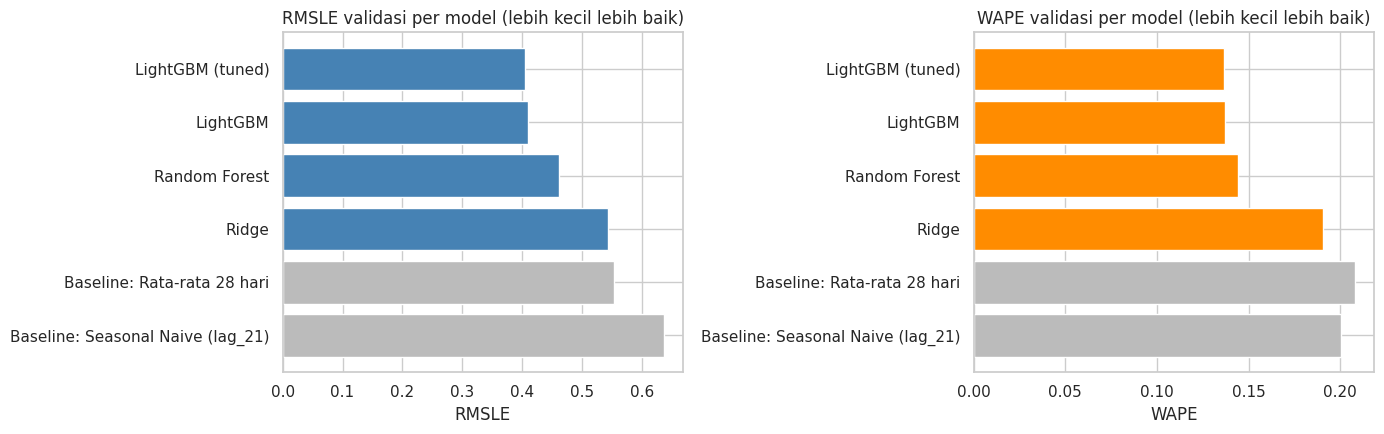

In [ ]:
# 8.2 Tabel perbandingan semua model
tabel_hasil = pd.DataFrame(HASIL).sort_values("RMSLE").reset_index(drop=True)
display(tabel_hasil.round(4))

bukan_baseline = tabel_hasil[~tabel_hasil.model.str.startswith("Baseline")]
model_utama = bukan_baseline.iloc[0]["model"]
print(f"Model dengan RMSLE validasi terendah (di luar baseline): {model_utama}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
urut = tabel_hasil.sort_values("RMSLE", ascending=False)
ax[0].barh(urut.model, urut.RMSLE, color=["#bbbbbb" if m.startswith("Baseline") else "steelblue" for m in urut.model])
ax[0].set_title("RMSLE validasi per model (lebih kecil lebih baik)"); ax[0].set_xlabel("RMSLE"); ax[0].set_ylabel("")
ax[1].barh(urut.model, urut.WAPE, color=["#bbbbbb" if m.startswith("Baseline") else "darkorange" for m in urut.model])
ax[1].set_title("WAPE validasi per model (lebih kecil lebih baik)"); ax[1].set_xlabel("WAPE"); ax[1].set_ylabel("")
simpan_fig("14_perbandingan_model")

**Interpretasi.** Baca dari atas ke bawah: (1) apakah model machine learning mengalahkan baseline naif dan seberapa jauh, (2) apakah urutan menurut RMSLE konsisten dengan urutan menurut WAPE/MAE (bila tidak, model berbeda dalam hal mana yang diperbaiki: kesalahan relatif atau absolut), (3) biaya waktu training. Selisih kecil antar model teratas sebaiknya dibaca bersama hasil CV di Bagian 7.5.

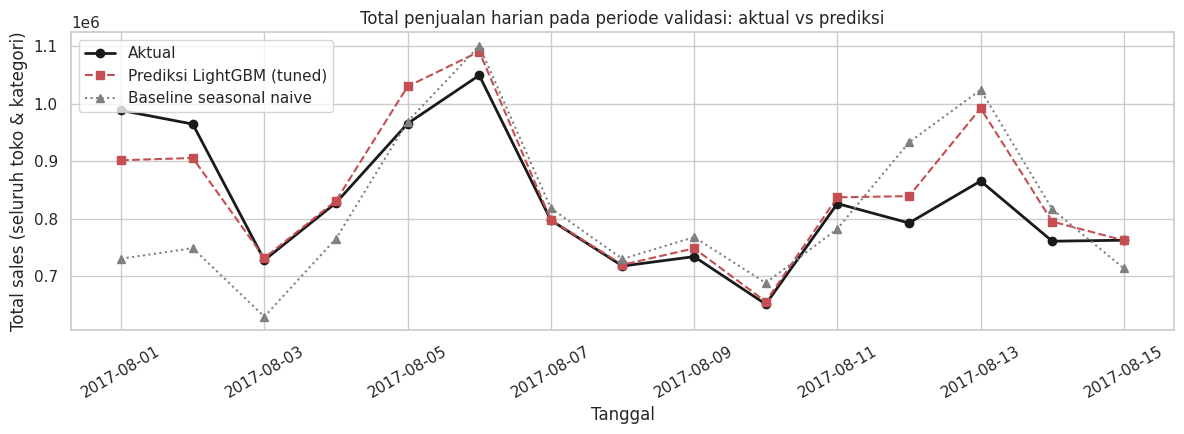

Selisih total harian prediksi vs aktual: rata-rata +1.7% | rentang -8.8% s/d +14.6%


In [ ]:
# 8.3 Aktual vs prediksi: total penjualan harian pada periode validasi
va_df = df_model.loc[va_mask, ["date", "store_nbr", "family", "sales"]].reset_index(drop=True)
va_df["y"] = y_val.values
for n in [model_utama, "Baseline: Seasonal Naive (lag_21)"]:
    va_df["pred_" + n] = np.expm1(PRED_VAL[n])

harian_val = va_df.groupby("date")[["sales"] + ["pred_" + n for n in [model_utama, "Baseline: Seasonal Naive (lag_21)"]]].sum()
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(harian_val.index, harian_val["sales"], "k-o", lw=2, label="Aktual")
ax.plot(harian_val.index, harian_val["pred_" + model_utama], "r--s", label=f"Prediksi {model_utama}")
ax.plot(harian_val.index, harian_val["pred_Baseline: Seasonal Naive (lag_21)"], color="gray", ls=":", marker="^", label="Baseline seasonal naive")
ax.set_title("Total penjualan harian pada periode validasi: aktual vs prediksi")
ax.set_xlabel("Tanggal"); ax.set_ylabel("Total sales (seluruh toko & kategori)"); ax.legend()
plt.xticks(rotation=30)
simpan_fig("15_aktual_vs_prediksi_harian")

selisih_pct = (harian_val["pred_" + model_utama] / harian_val["sales"] - 1) * 100
print(f"Selisih total harian prediksi vs aktual: rata-rata {selisih_pct.mean():+.1f}% | rentang {selisih_pct.min():+.1f}% s/d {selisih_pct.max():+.1f}%")

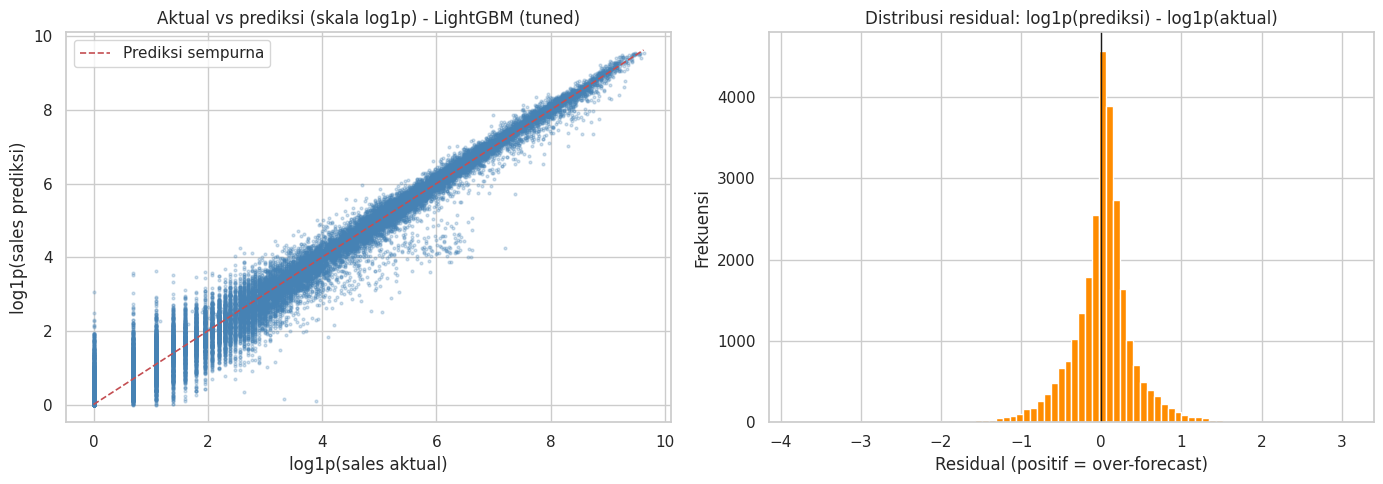

Residual log: rata-rata +0.015 | median +0.032 | porsi over-forecast 57.0%


In [ ]:
# 8.4 Scatter aktual vs prediksi & distribusi residual
sampel = va_df.sample(min(30_000, len(va_df)), random_state=SEED)
resid_log = np.log1p(va_df["pred_" + model_utama]) - va_df["y"]

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].scatter(np.log1p(sampel.sales), np.log1p(sampel["pred_" + model_utama]), s=4, alpha=0.25, color="steelblue")
lim = [0, max(np.log1p(sampel.sales).max(), np.log1p(sampel["pred_" + model_utama]).max())]
ax[0].plot(lim, lim, "r--", lw=1.2, label="Prediksi sempurna")
ax[0].set_title(f"Aktual vs prediksi (skala log1p) - {model_utama}")
ax[0].set_xlabel("log1p(sales aktual)"); ax[0].set_ylabel("log1p(sales prediksi)"); ax[0].legend()
ax[1].hist(resid_log, bins=80, color="darkorange")
ax[1].axvline(0, color="k", lw=1)
ax[1].set_title("Distribusi residual: log1p(prediksi) - log1p(aktual)")
ax[1].set_xlabel("Residual (positif = over-forecast)"); ax[1].set_ylabel("Frekuensi")
simpan_fig("16_scatter_dan_residual")
print(f"Residual log: rata-rata {resid_log.mean():+.3f} | median {resid_log.median():+.3f} | "
      f"porsi over-forecast {(resid_log > 0).mean():.1%}")

**Interpretasi.** Titik yang rapat di sekitar garis merah menandakan prediksi akurat; sebaran melebar pada nilai kecil biasanya berasal dari deret yang sangat sporadis (banyak nol). Pada histogram residual, pusat yang bergeser dari 0 menandakan **bias sistematis** (cenderung over- atau under-forecast); ekor panjang menunjukkan beberapa kasus meleset besar. Bias ke arah mana yang lebih merugikan bergantung pada biaya bisnis (Bagian 1).

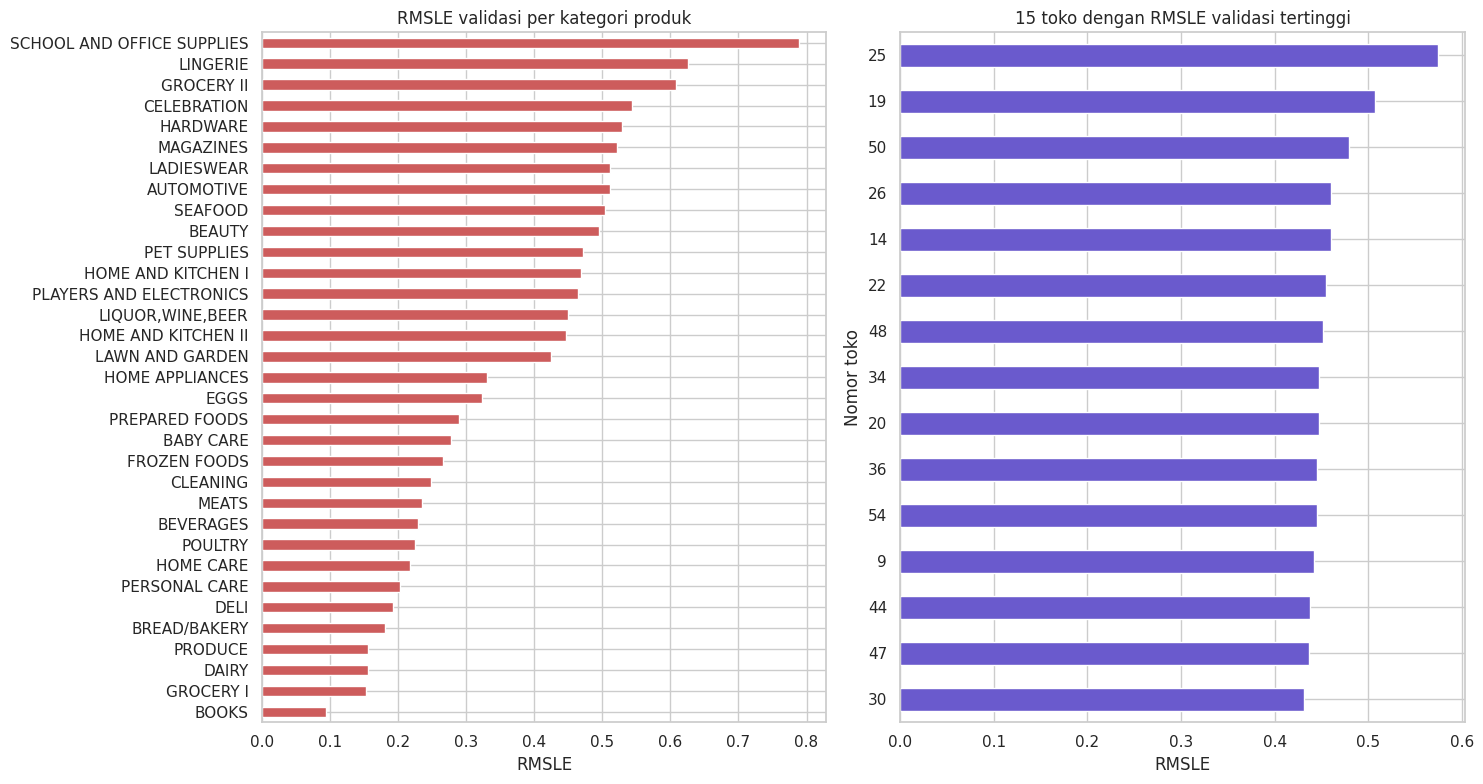

Kategori paling sulit diprediksi: ['SCHOOL AND OFFICE SUPPLIES', 'LINGERIE', 'GROCERY II'] | proporsi nol di data train penuh: {'SCHOOL AND OFFICE SUPPLIES': 0.74, 'LINGERIE': 0.16, 'GROCERY II': 0.12}
Kategori paling mudah: ['BOOKS', 'GROCERY I', 'DAIRY'] | proporsi nol: {'BOOKS': 0.97, 'GROCERY I': 0.08, 'DAIRY': 0.08}


In [ ]:
# 8.5 Di mana model sulit? Error per kategori produk dan per toko
va_df["err2"] = (np.log1p(va_df["pred_" + model_utama]) - va_df["y"]) ** 2
va_df["abs_err"] = (va_df["pred_" + model_utama] - va_df["sales"]).abs()

per_family = va_df.groupby("family", observed=True).agg(RMSLE=("err2", lambda s: np.sqrt(s.mean())),
                                                         total_sales=("sales", "sum"), total_abs_err=("abs_err", "sum"))
per_family["WAPE"] = per_family.total_abs_err / per_family.total_sales.replace(0, np.nan)
per_toko = va_df.groupby("store_nbr", observed=True).agg(RMSLE=("err2", lambda s: np.sqrt(s.mean())))

fig, ax = plt.subplots(1, 2, figsize=(15, 8))
per_family.RMSLE.sort_values().plot.barh(ax=ax[0], color="indianred")
ax[0].set_title("RMSLE validasi per kategori produk"); ax[0].set_xlabel("RMSLE"); ax[0].set_ylabel("")
per_toko.RMSLE.sort_values(ascending=False).head(15)[::-1].plot.barh(ax=ax[1], color="slateblue")
ax[1].set_title("15 toko dengan RMSLE validasi tertinggi"); ax[1].set_xlabel("RMSLE"); ax[1].set_ylabel("Nomor toko")
simpan_fig("17_error_per_family_dan_toko")

terburuk = per_family.RMSLE.sort_values(ascending=False).head(3).index.tolist()
terbaik = per_family.RMSLE.sort_values().head(3).index.tolist()
print("Kategori paling sulit diprediksi:", terburuk, "| proporsi nol di data train penuh:",
      {f: round(float(nol_family.get(f, np.nan)), 2) for f in terburuk})
print("Kategori paling mudah:", terbaik, "| proporsi nol:", {f: round(float(nol_family.get(f, np.nan)), 2) for f in terbaik})

**Interpretasi.** Cocokkan daftar "paling sulit" dan "paling mudah" dengan proporsi nol yang dicetak. Polanya bukan sekadar "banyak nol = sulit": kategori yang **hampir selalu nol** mudah ditebak (prediksi nol sudah benar), kategori **besar dan stabil** juga mudah, sedangkan kategori **intermiten** (campuran hari nol dan hari terjual dalam jumlah kecil, sehingga selisih relatifnya besar) paling sulit pada metrik relatif seperti RMSLE. Periksa apakah itu yang terjadi pada hasil kalian. Ini sifat data, bukan semata kelemahan algoritma. Implikasi bisnisnya: kategori intermiten butuh kebijakan stok terpisah (mis. *safety stock*), dan model jangan dinilai hanya dari rata-rata global.

,model,RMSLE_train,RMSLE_validasi,selisih_val_train,CV_RMSLE_mean
0,LightGBM (tuned),0.3997,0.4045,0.0049,0.3952
1,LightGBM,0.3969,0.4105,0.0136,0.3917
2,Random Forest,0.5088,0.4616,-0.0472,0.4005
3,Ridge,0.6504,0.5443,-0.1061,0.4375


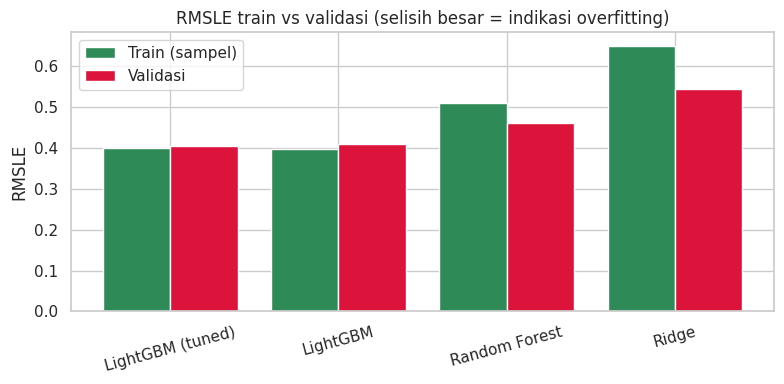

In [ ]:
# 8.6 Cek overfitting: RMSLE train vs validasi vs CV
cek = tabel_hasil[~tabel_hasil.model.str.startswith("Baseline")][["model", "RMSLE_train", "RMSLE"]].rename(
    columns={"RMSLE": "RMSLE_validasi"})
cek["selisih_val_train"] = cek.RMSLE_validasi - cek.RMSLE_train
cek["CV_RMSLE_mean"] = cek.model.map(lambda n: np.mean(CV_HASIL[n]) if n in CV_HASIL else np.nan)
display(cek.round(4))

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(cek))
ax.bar(x - 0.2, cek.RMSLE_train, 0.4, label="Train (sampel)", color="seagreen")
ax.bar(x + 0.2, cek.RMSLE_validasi, 0.4, label="Validasi", color="crimson")
ax.set_xticks(x); ax.set_xticklabels(cek.model, rotation=15)
ax.set_title("RMSLE train vs validasi (selisih besar = indikasi overfitting)"); ax.set_ylabel("RMSLE"); ax.legend()
simpan_fig("18_cek_overfitting")

**Interpretasi.** Jika RMSLE train jauh lebih kecil dibanding validasi, model menghafal data latih (*overfitting*): biasanya terjadi pada model fleksibel (Random Forest/LightGBM) dan harus dibaca bersama CV. Karena validasi hanya 15 hari dan bisa kebetulan mudah/sulit, selisih val-train yang kecil **tidak otomatis** berarti baik; bandingkan juga dengan simpangan baku CV pada Bagian 7.5.

## 9. Pemilihan Model Terbaik
*Penanggung jawab: Samudra Tsalasa Putra*

Pemilihan tidak hanya berdasarkan satu angka. Kriteria: (1) akurasi validasi (RMSLE, didukung WAPE/MAE), (2) konsistensi pada cross-validation, (3) risiko overfitting, (4) interpretabilitas, (5) biaya komputasi.

In [ ]:
interpretabilitas = {"Ridge": "Tinggi (koefisien)", "Random Forest": "Sedang (importance)",
                     "LightGBM": "Sedang (gain/SHAP)", "LightGBM (tuned)": "Sedang (gain/SHAP)"}
keputusan = bukan_baseline[["model", "RMSLE", "WAPE", "MAE", "waktu_train_detik"]].copy()
keputusan["CV_RMSLE_mean"] = keputusan.model.map(lambda n: np.mean(CV_HASIL[n]) if n in CV_HASIL else np.nan)
keputusan["CV_RMSLE_std"] = keputusan.model.map(lambda n: np.std(CV_HASIL[n]) if len(CV_HASIL.get(n, [])) > 1 else np.nan)
keputusan["interpretabilitas"] = keputusan.model.map(interpretabilitas)
display(keputusan.round(4))

best_name = keputusan.sort_values("RMSLE").iloc[0]["model"]
cv_only = keputusan.dropna(subset=["CV_RMSLE_std"]).sort_values("CV_RMSLE_mean")
best_cv = cv_only.iloc[0]["model"] if len(cv_only) else best_name
baseline_terbaik = tabel_hasil[tabel_hasil.model.str.startswith("Baseline")].RMSLE.min()
baris_best = keputusan[keputusan.model == best_name].iloc[0]

print(f"Model terbaik menurut RMSLE validasi : {best_name} (RMSLE = {baris_best.RMSLE:.4f})")
print(f"Model terbaik menurut rata-rata CV   : {best_cv}")
print(f"Perbaikan terhadap baseline terbaik  : {(1 - baris_best.RMSLE / baseline_terbaik) * 100:.1f}% lebih rendah RMSLE")
print("Konsisten antara validasi dan CV." if best_cv == best_name or best_name.startswith(best_cv)
      else "Catatan: validasi dan CV memberi urutan berbeda -> jelaskan di laporan alasan memilih salah satu.")

,model,RMSLE,WAPE,MAE,waktu_train_detik,CV_RMSLE_mean,CV_RMSLE_std,interpretabilitas
0,LightGBM (tuned),0.4045,0.1364,63.4541,116.6,0.3952,NaN,Sedang (gain/SHAP)
1,LightGBM,0.4105,0.1369,63.6834,98.5,0.3917,0.0116,Sedang (gain/SHAP)
2,Random Forest,0.4616,0.1444,67.1540,124.0,0.4005,0.0105,Sedang (importance)
3,Ridge,0.5443,0.1906,88.6436,19.1,0.4375,0.0109,Tinggi (koefisien)


Model terbaik menurut RMSLE validasi : LightGBM (tuned) (RMSLE = 0.4045)
Model terbaik menurut rata-rata CV   : LightGBM
Perbaikan terhadap baseline terbaik  : 26.9% lebih rendah RMSLE
Konsisten antara validasi dan CV.


### Argumen pemilihan model (lengkapi/sesuaikan setelah melihat hasil asli)
Gunakan output di atas untuk menjawab pertanyaan berikut dalam laporan:
1. **Akurasi:** model mana yang RMSLE-nya terendah, dan apakah ia juga unggul pada WAPE/MAE? Seberapa besar selisihnya dengan model kedua?
2. **Konsistensi:** apakah juara validasi juga juara rata-rata CV dengan simpangan baku kecil?
3. **Overfitting:** apakah selisih train-validasi masih wajar (Bagian 8.6)?
4. **Interpretabilitas vs akurasi:** bila selisih akurasi dengan Ridge kecil, apakah kompleksitas model ensemble sepadan? Ridge lebih mudah dijelaskan ke manajer toko; LightGBM/Random Forest dijelaskan lewat *feature importance* dan SHAP.
5. **Biaya komputasi:** lihat kolom `waktu_train_detik`; untuk peramalan rutin harian/mingguan, model yang cepat dilatih ulang punya nilai praktis.

**Catatan penting tentang CV model tuned:** skor CV `LightGBM (tuned)` berasal dari proses tuning pada `TUNE_ROWS` baris terbaru, sehingga tidak sebanding langsung dengan CV model lain yang memakai seluruh data train.

**Keterbatasan:** validasi 15 hari hanya satu "jendela" waktu; hasil bisa berbeda di musim lain (mis. Desember).

## 10. Interpretasi Model
*Penanggung jawab: Hany Nadya Fairuz*

Kami menafsirkan model LightGBM terbaik (versi *tuned* atau default, mana yang RMSLE validasinya lebih rendah) memakai *feature importance* (*gain*) dan SHAP.

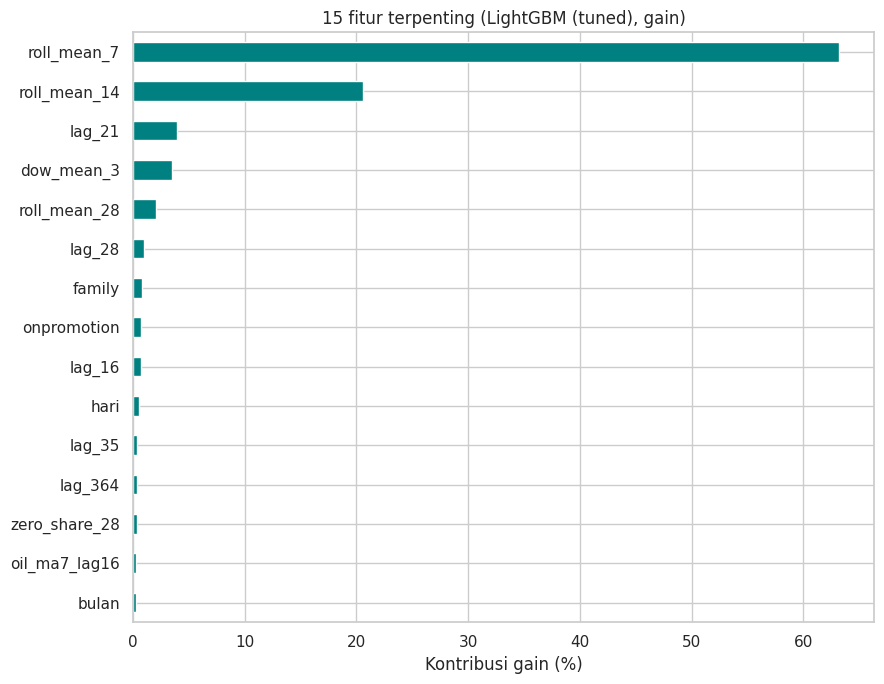

,fitur,kontribusi_%,arti_bisnis
0,roll_mean_7,63.17,"Rata-rata level penjualan terbaru (7 hari, ter..."
1,roll_mean_14,20.60,Rata-rata level penjualan 14 hari (tergeser 16...
2,lag_21,3.95,Penjualan pada hari yang sama 3 minggu lalu (p...
3,dow_mean_3,3.52,Rata-rata hari-yang-sama dari 3 minggu terpisa...
4,roll_mean_28,2.02,Rata-rata level penjualan 28 hari: level dasar...
5,lag_28,1.00,Penjualan pada hari yang sama 4 minggu lalu (p...
6,family,0.84,Kategori produk.
7,onpromotion,0.69,Jumlah item yang sedang dipromosikan; promo me...
8,lag_16,0.67,Penjualan 16 hari lalu: lag terdekat yang ters...
9,hari,0.53,Tanggal dalam bulan.


,kontribusi_%
lag/rolling penjualan,96.31
kalender/gajian,1.34
identitas toko/kategori,1.11
promosi,0.69
"ekonomi/keramaian (minyak, transaksi)",0.48
libur/event/gempa,0.07


In [ ]:
# 10.1 Feature importance (gain) dari LightGBM terbaik
nama_lgb = min(["LightGBM", "LightGBM (tuned)"], key=lambda n: tabel_hasil.set_index("model").loc[n, "RMSLE"])
model_lgb = MODEL[nama_lgb]
if not best_name.startswith("LightGBM"):
    print(f"Catatan: model terbaik keseluruhan adalah {best_name}; interpretasi di bawah memakai {nama_lgb} karena paling mudah ditafsirkan.")

imp = pd.Series(model_lgb.booster_.feature_importance(importance_type="gain"), index=FITUR).sort_values(ascending=False)
imp_pct = (imp / imp.sum() * 100)

fig, ax = plt.subplots(figsize=(9, 7))
imp_pct.head(15)[::-1].plot.barh(ax=ax, color="teal")
ax.set_title(f"15 fitur terpenting ({nama_lgb}, gain)")
ax.set_xlabel("Kontribusi gain (%)"); ax.set_ylabel("")
simpan_fig("19_feature_importance")

top10 = pd.DataFrame({"fitur": imp_pct.head(10).index, "kontribusi_%": imp_pct.head(10).round(2).values,
                      "arti_bisnis": [KAMUS_FITUR.get(f, "-") for f in imp_pct.head(10).index]})
display(top10)

kelompok = {"lag/rolling penjualan": [f for f in FITUR if f.startswith(("lag_", "roll_", "dow_mean", "selisih", "zero_share"))],
            "identitas toko/kategori": ["store_nbr", "family", "tipe_toko", "city", "state", "cluster"],
            "promosi": ["onpromotion"],
            "kalender/gajian": [f for f in FITUR if f in ["bulan", "hari", "hari_minggu", "minggu_tahun", "akhir_pekan", "is_payday",
                                                          "is_month_start", "is_month_end", "dow_sin", "dow_cos", "month_sin", "month_cos"]],
            "libur/event/gempa": [f for f in FITUR if f.startswith(("libur", "event", "hari_kerja", "pasca"))],
            "ekonomi/keramaian (minyak, transaksi)": ["oil_lag16", "oil_ma7_lag16", "trans_roll28_lag16"]}
kontribusi_grup = pd.Series({g: imp_pct.reindex(f).sum() for g, f in kelompok.items()}).sort_values(ascending=False)
display(kontribusi_grup.round(2).to_frame("kontribusi_%"))

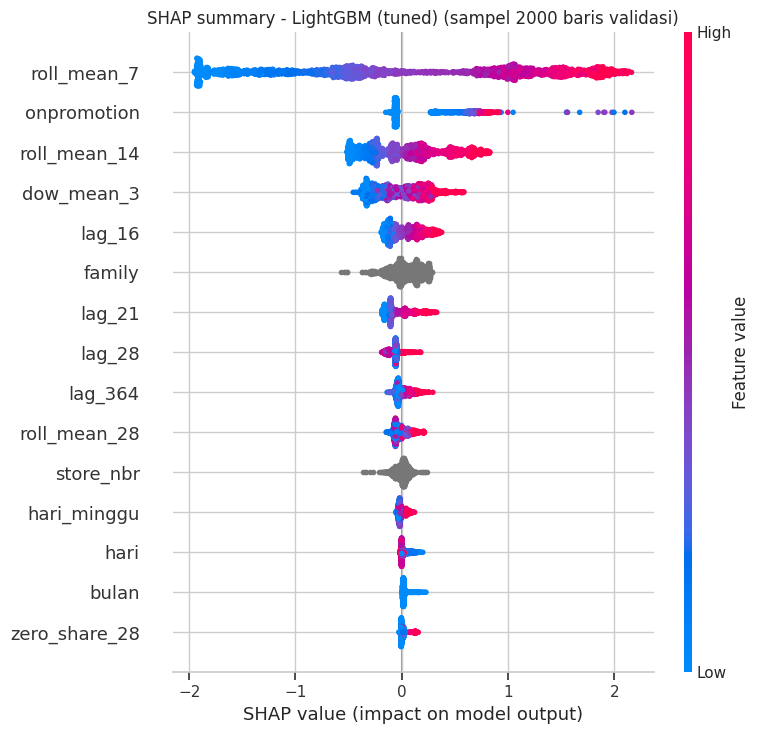

In [ ]:
# 10.2 SHAP summary plot (sampel kecil agar cepat)
if RUN_SHAP:
    try:
        import shap
        Xs = X_val.sample(min(2000, len(X_val)), random_state=SEED)
        sv = shap.TreeExplainer(model_lgb).shap_values(Xs)
        plt.figure()
        shap.summary_plot(sv, Xs, max_display=15, show=False)
        plt.title(f"SHAP summary - {nama_lgb} (sampel {len(Xs)} baris validasi)")
        simpan_fig("20_shap_summary")
    except Exception as e:
        print("SHAP dilewati karena error:", repr(e))
else:
    print("RUN_SHAP = False, SHAP dilewati.")

**Interpretasi (panduan membaca; sesuaikan dengan output).**
- **Tabel top-10 & kontribusi grup:** fitur apa yang paling dominan? Biasanya kelompok *lag/rolling* mendominasi karena penjualan sangat persisten, dan itu wajar. Yang menarik bagi bisnis adalah kontribusi **promo, libur, dan gajian** setelah level dasar diperhitungkan.
- **SHAP:** sumbu-x menunjukkan dampak fitur terhadap prediksi `log1p(sales)`; warna menunjukkan nilai fitur (merah = tinggi). Contoh pembacaan: titik merah `roll_mean_28` di sisi kanan berarti level penjualan historis tinggi mendorong prediksi naik.
- **Peringatan:** *importance* dan SHAP menunjukkan apa yang **dipakai model**, bukan hubungan sebab-akibat. Mis. `onpromotion` penting bisa karena kategori besar sering dipromosikan.

## 11. (Opsional) Forecast 15 Hari ke Depan
*Penanggung jawab: Selsa Trikartika*

> **Bagian opsional dan tidak dinilai dengan skor**, karena `test.csv` tidak memiliki label `sales`. Tujuannya menunjukkan bahwa model dapat dipakai nyata dan menyiapkan keluaran untuk sebuah aplikasi sederhana.

**Pendekatan:** model terbaik dilatih ulang pada **seluruh data berlabel** (train + validasi), lalu meramal 15 hari test. Karena semua fitur memakai lag ≥ 16 hari, setiap hari test (hari ke-1 sampai ke-15) dapat dihitung dari data yang sudah diketahui, jadi tidak perlu ramalan rekursif.

In [ ]:
# 11.1 Latih ulang model terbaik pada seluruh data berlabel, lalu prediksi test
tr_all = ~df_model.is_test
te_mask = df_model.is_test
fab_final, mr_final = FABRIK[best_name]
Xa, ya = sampel_baris(df_model.loc[tr_all, FITUR], df_model.loc[tr_all, "y"], mr_final)

t0 = time.time()
model_final = fab_final()
model_final.fit(Xa, ya)
print(f"Model final ({best_name}) dilatih ulang pada {len(Xa):,} baris dalam {time.time()-t0:.0f} dtk")

X_test = df_model.loc[te_mask, FITUR]
pred_test = np.expm1(np.clip(model_final.predict(X_test), 0, None))          # kembali ke skala asli, tidak negatif

hasil_test = df_model.loc[te_mask, ["id", "date", "store_nbr", "family"]].copy()
hasil_test["sales_pred"] = pred_test
hasil_test["id"] = hasil_test["id"].astype(int)
hasil_test["store_nbr"] = hasil_test["store_nbr"].astype(int)
hasil_test["family"] = hasil_test["family"].astype(str)
hasil_test = hasil_test.sort_values("id").reset_index(drop=True)
print("Baris prediksi test:", len(hasil_test), "| rentang tanggal:", hasil_test.date.min().date(), "s/d", hasil_test.date.max().date())
display(hasil_test.head())

Model final (LightGBM (tuned)) dilatih ulang pada 1,703,592 baris dalam 120 dtk
Baris prediksi test: 28512 | rentang tanggal: 2017-08-16 s/d 2017-08-31


,id,date,store_nbr,family,sales_pred
0,3000888,2017-08-16,1,AUTOMOTIVE,4.219532
1,3000889,2017-08-16,1,BABY CARE,0.073282
2,3000890,2017-08-16,1,BEAUTY,4.431825
3,3000891,2017-08-16,1,BEVERAGES,2489.134772
4,3000892,2017-08-16,1,BOOKS,0.197698


In [ ]:
# 11.2 Simpan submission.csv (format sample_submission), forecast & histori untuk aplikasi
submission = hasil_test[["id"]].assign(sales=hasil_test["sales_pred"].values)
submission.to_csv("submission.csv", index=False)
hasil_test.assign(date=hasil_test.date.dt.strftime("%Y-%m-%d")).to_csv("forecast_15d.csv", index=False)

hist = df_model.loc[(~df_model.is_test) & (df_model.date > TRAIN_END - pd.Timedelta(days=90)), ["date", "store_nbr", "family", "sales"]].copy()
hist["store_nbr"] = hist["store_nbr"].astype(int); hist["family"] = hist["family"].astype(str)
hist.assign(date=hist.date.dt.strftime("%Y-%m-%d")).to_csv("histori_90d.csv", index=False)

sample_sub_path = os.path.join(DATA, "sample_submission.csv")
if os.path.exists(sample_sub_path):
    ss = pd.read_csv(sample_sub_path)
    if set(ss.id) == set(submission.id):
        print("Format submission.csv sesuai sample_submission (id lengkap).")
    else:
        print(f"Catatan: submission berisi {len(submission):,} dari {len(ss):,} id. Wajar jika SAMPLE_STORES dipakai; "
              f"untuk submission lengkap jalankan dengan SAMPLE_STORES = None.")
print("Tersimpan: submission.csv, forecast_15d.csv, histori_90d.csv")
try:
    import joblib
    joblib.dump(model_final, "model_final.joblib")
    print("Tersimpan: model_final.joblib")
except Exception as e:
    print("Model tidak tersimpan:", repr(e))

Format submission.csv sesuai sample_submission (id lengkap).
Tersimpan: submission.csv, forecast_15d.csv, histori_90d.csv
Tersimpan: model_final.joblib


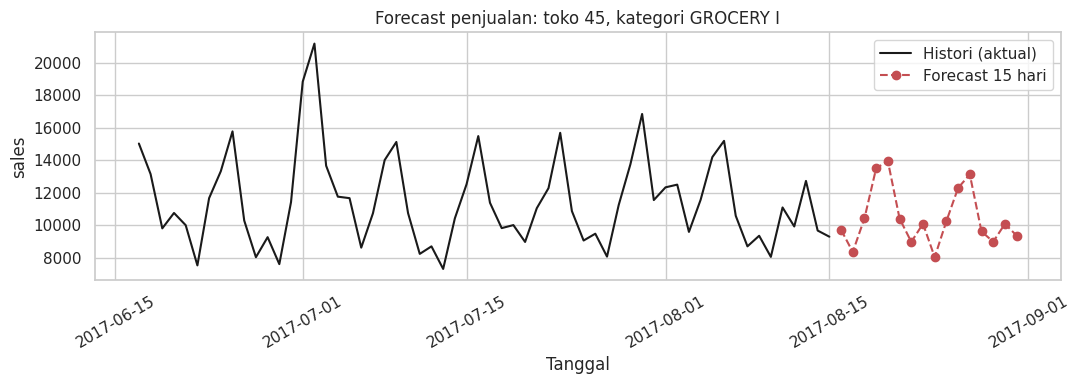

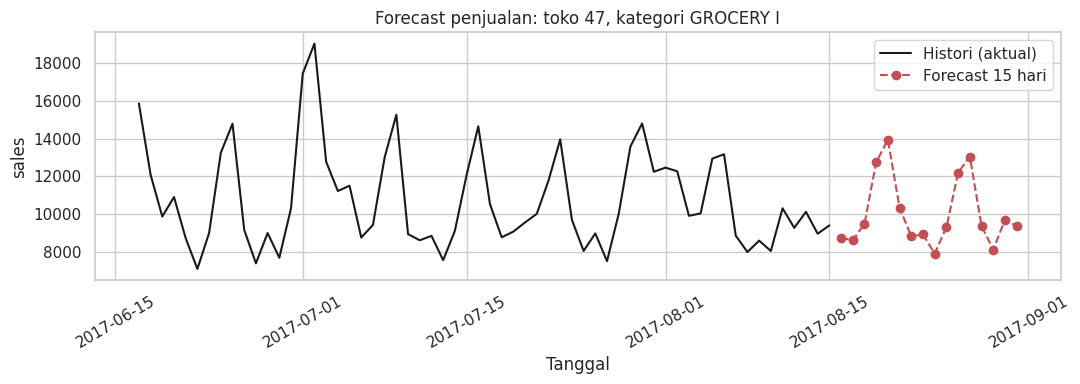

In [ ]:
# 11.3 Fungsi bantu: grafik histori 60 hari + forecast 15 hari untuk satu toko & kategori
def plot_forecast(store_nbr, family, hari_histori=60):
    h = hist[(hist.store_nbr == store_nbr) & (hist.family == family)].sort_values("date").tail(hari_histori)
    f = hasil_test[(hasil_test.store_nbr == store_nbr) & (hasil_test.family == family)].sort_values("date")
    if len(f) == 0:
        print("Kombinasi toko/kategori tidak ada pada data (periksa SAMPLE_STORES)."); return
    fig, ax = plt.subplots(figsize=(11, 4))
    ax.plot(h.date, h.sales, "k-", label="Histori (aktual)")
    ax.plot(f.date, f.sales_pred, "r--o", label="Forecast 15 hari")
    ax.set_title(f"Forecast penjualan: toko {store_nbr}, kategori {family}")
    ax.set_xlabel("Tanggal"); ax.set_ylabel("sales"); ax.legend(); plt.xticks(rotation=30)
    simpan_fig(f"21_forecast_toko{store_nbr}_{family.replace('/', '_').replace(' ', '_')}")

kontribusi_tot = hist.groupby(["store_nbr", "family"]).sales.sum().sort_values(ascending=False)
for (s, fam) in kontribusi_tot.head(2).index:
    plot_forecast(int(s), fam)

In [ ]:
# 11.4 Mini-app Streamlit (opsional): membaca forecast_15d.csv dan histori_90d.csv
kode_app = """
import pandas as pd
import streamlit as st

st.set_page_config(page_title="Forecast Penjualan Favorita", layout="wide")
st.title("Forecast Penjualan 15 Hari - Toko Favorita")

fc = pd.read_csv("forecast_15d.csv", parse_dates=["date"])
hs = pd.read_csv("histori_90d.csv", parse_dates=["date"])

toko = st.sidebar.selectbox("Toko", sorted(fc.store_nbr.unique()))
kategori = st.sidebar.selectbox("Kategori produk", sorted(fc.family.unique()))

f = fc[(fc.store_nbr == toko) & (fc.family == kategori)].set_index("date")["sales_pred"].rename("Forecast")
h = hs[(hs.store_nbr == toko) & (hs.family == kategori)].set_index("date")["sales"].rename("Histori")
st.line_chart(pd.concat([h, f], axis=1))
st.metric("Total forecast 15 hari", f"{f.sum():,.0f}")
st.dataframe(f.reset_index())
"""
with open("app_forecast.py", "w", encoding="utf-8") as fh:
    fh.write(kode_app.strip() + "\n")
print("Tersimpan: app_forecast.py  -> jalankan secara lokal dengan: pip install streamlit && streamlit run app_forecast.py")

Tersimpan: app_forecast.py  -> jalankan secara lokal dengan: pip install streamlit && streamlit run app_forecast.py


**Catatan untuk laporan:** file `app_forecast.py` hanyalah contoh aplikasi sederhana yang membaca CSV hasil ramalan; ia berjalan di komputer lokal (bukan di dalam notebook).

## 12. Kesimpulan & Insight Bisnis
*Penanggung jawab: Samudra Tsalasa Putra*

In [ ]:
# 12.1 Ringkasan otomatis hasil akhir (tabel siap salin ke laporan)
ringkasan = tabel_hasil[["model", "RMSLE", "RMSE", "MAE", "R2", "WAPE", "waktu_train_detik"]].round(4)
display(ringkasan)
ringkasan.to_csv("ringkasan_perbandingan_model.csv", index=False)

print("\n=== RINGKASAN OTOMATIS (periksa kecocokan dengan interpretasi kelompok) ===")
print(f"- Data model: {len(TOKO)} toko x {len(FAMILY)} kategori, {START_DATE} s/d {TRAIN_END.date()}; validasi {VAL_DAYS} hari terakhir.")
print(f"- Model terbaik: {best_name} dengan RMSLE validasi {baris_best.RMSLE:.4f} "
      f"({(1 - baris_best.RMSLE / baseline_terbaik) * 100:.1f}% lebih rendah dari baseline terbaik).")
print(f"- WAPE model terbaik: {baris_best.WAPE:.1%}; MAE: {baris_best.MAE:,.1f} unit per toko-kategori-hari.")
print(f"- Kelompok fitur paling berpengaruh ({nama_lgb}): {kontribusi_grup.index[0]} ({kontribusi_grup.iloc[0]:.0f}% gain), "
      f"lalu {kontribusi_grup.index[1]} ({kontribusi_grup.iloc[1]:.0f}%).")
print(f"- Kategori tersulit diprediksi: {terburuk}; termudah: {terbaik}.")

,model,RMSLE,RMSE,MAE,R2,WAPE,waktu_train_detik
0,LightGBM (tuned),0.4045,214.9178,63.4541,0.9702,0.1364,116.6
1,LightGBM,0.4105,216.5953,63.6834,0.9697,0.1369,98.5
2,Random Forest,0.4616,235.3752,67.1540,0.9642,0.1444,124.0
3,Ridge,0.5443,312.3652,88.6436,0.9370,0.1906,19.1
4,Baseline: Rata-rata 28 hari,0.5536,323.1779,96.7419,0.9325,0.2080,0.0
5,Baseline: Seasonal Naive (lag_21),0.6371,334.5431,93.3169,0.9277,0.2006,0.0



=== RINGKASAN OTOMATIS (periksa kecocokan dengan interpretasi kelompok) ===
- Data model: 54 toko x 33 kategori, 2015-01-01 s/d 2017-08-15; validasi 15 hari terakhir.
- Model terbaik: LightGBM (tuned) dengan RMSLE validasi 0.4045 (26.9% lebih rendah dari baseline terbaik).
- WAPE model terbaik: 13.6%; MAE: 63.5 unit per toko-kategori-hari.
- Kelompok fitur paling berpengaruh (LightGBM (tuned)): lag/rolling penjualan (96% gain), lalu kalender/gajian (1%).
- Kategori tersulit diprediksi: ['SCHOOL AND OFFICE SUPPLIES', 'LINGERIE', 'GROCERY II']; termudah: ['BOOKS', 'GROCERY I', 'DAIRY'].


### 12.2 Kerangka kesimpulan (lengkapi berdasarkan hasil asli)
**Temuan utama.** (a) Pola waktu (mingguan, tahunan, gajian, libur) kuat dan terukur; (b) penjualan sangat persisten sehingga fitur *lag/rolling* paling informatif; (c) model terbaik berdasarkan Bagian 9 dan seberapa jauh ia mengalahkan baseline; (d) kategori sporadis paling sulit diprediksi.

**Rekomendasi tindakan (diuji dulu terhadap hasil, jangan disalin mentah):**
- *Stok:* gunakan ramalan 15 hari untuk perencanaan pengisian ulang; beri **penyangga stok lebih besar** pada kategori yang RMSLE-nya tinggi (Bagian 8.5).
- *Kalender operasional:* siapkan stok dan staf lebih awal sebelum libur nasional, tanggal gajian (15 dan akhir bulan), dan akhir tahun, bila terbukti dari EDA dan fitur penting.
- *Promosi:* jadwalkan promo dengan mempertimbangkan efeknya per kategori (Bagian 3.10), bukan rata-rata global.
- *Monitoring:* latih ulang model secara berkala dan pantau bias (over/under-forecast) per kategori.

**Keterbatasan analisis.**
1. Validasi hanya 15 hari (satu jendela waktu); CV memberi gambaran lebih luas tetapi tetap terbatas.
2. Model tidak bisa meramalkan kejadian luar biasa baru (mis. gempa lain); `pasca_gempa` hanya membantu belajar dari masa lalu.
3. Fitur promo dan libur diasumsikan diketahui di masa depan (benar untuk jadwal yang direncanakan, tetapi tidak untuk promo mendadak).
4. Random Forest dilatih pada sampel baris dan tuning hanya dilakukan pada LightGBM dengan ruang pencarian kecil; perbandingan antar model karenanya tidak sepenuhnya "setara".
5. Bila `SAMPLE_STORES`/`START_DATE` dipakai, hasil berlaku untuk subset tersebut.

**Saran pengembangan lanjut.** Model per kelompok kategori, fitur interaksi promo × kategori, *quantile regression* untuk interval ketidakpastian (penting bagi keputusan stok), validasi pada lebih banyak jendela (termasuk Desember), model deret waktu klasik/Prophet sebagai pembanding, dan penanganan hierarkis (toko → kategori).

## 13. Referensi
*Penanggung jawab: Samudra Tsalasa Putra*

- Kaggle Competition: *Store Sales - Time Series Forecasting* — https://www.kaggle.com/competitions/store-sales-time-series-forecasting
- Dokumentasi scikit-learn: `TimeSeriesSplit`, `Ridge`, `RandomForestRegressor`, `RandomizedSearchCV`, `ColumnTransformer`
- Hyndman & Athanasopoulos, *Forecasting: Principles and Practice* (bab evaluasi akurasi & validasi deret waktu)
- Materi studi independen Celerates — Data Science & Generative AI